# C1 – Week 3 · Noise filtering, texture descriptors and retrieval of up to two paintings per photo
**Team 4** · Master in Computer Vision · Module C1 (Introduction to Human and Computer Vision)

This notebook contains **all the work of week 3**: every experiment is run here, every number in the slides comes from here,
and every decision is justified with an experiment and a conclusion. It is written so that someone who has not followed the
project can read it from top to bottom.

### What the week asks

| Task | What is asked | Where |
|---|---|---|
| 1 | Filter the noise with linear or non-linear filters (unknown noise model, only some images are noisy). Show examples from QSD1-W3 | §2 |
| 2 | Implement texture descriptors (LBP, DCT, wavelet-based, …) and evaluate the query system on QSD1-W3 **using only texture descriptors** | §3 |
| 3 | QSD2-W3: detect **all** the paintings (max. 2 per image), remove the background, create a binary mask and evaluate it | §4 |
| 4 | QSD2-W3: detect the paintings, remove background, retrieve, return the correspondences with an **extra list level** (`[[[7,25,…],[44,81,…]], …]`) | §5 |
| 5 | Blind submission on QST1 / QST2 (top-10 per painting, one method; masks for QST2) | §6 + `run_w3.py` |

### What changes with respect to weeks 1–2

* **Noise:** some query photos have impulse-like noise. Colour histograms and, above all, texture descriptors react to it.
* **Colour changes:** some queries have a random **hue** change. A colour descriptor sees a different painting.
* **Two paintings per photo:** the W2 background removal kept the largest component; now we need *all* paintings (up to 2) and their order.

### The lessons we carry from the previous weeks

* **W1 → W2:** tuning on 30 queries overfits (W1: 0.90 in dev, 0.77 in test). Since W2 we validate every choice on several
  independent development sets and only keep choices that sit on a **plateau** (their neighbours also work).
* **Class results of W2** (slide 3 of the W3 statement): our team had the **best QST2 retrieval (mAP@1 0.90)** and grade 10 in W1 and W2.
  For the **masks**, the best QST2 F1 (0.98) belongs to Teams 2, 8 and 3; ours was 0.96. Team 8's code is public, so this week we
  **start the background removal from Team 8's wall model** (best test masks we can reproduce) and adapt it to two paintings,
  and we keep **our own W2 colour descriptor** (best test retrieval) as one of the descriptors of the final system.

### Final pipeline in one picture (details and evidence in each section)

```
photo ──► noise detector ──► (median 3×3, twice, only if noisy)
       └─► [QSD2/QST2] wall model (Team 8) ─► up to 2 paintings ─► crop each painting
       └─► descriptors:  HOG (texture: gradient orientations)  +  Haar wavelet (texture: multi-scale energy)  +  W2 colour pyramid
       └─► per-query z-score of each distance ─► sum ─► top-10 BBDD ids per painting
```

## 0. Setup

**How to run it.** Put this notebook in `Project/week3/` together with `qsd1_w3/` and `qsd2_w3/` (as downloaded, the
images are inside `qsd1_w3/qsd1_w3/…`; the loader finds them). The museum database `BBDD/` is read from `week3/BBDD` and,
if it is not there, from `../week2/week2_submission/BBDD` or `../week1/BBDD`. The W2 development sets (`qsd1_w2`, `qsd2_w2`) are used as
**extra validation**; they are read from `week3/` or from `../week2/…` and are skipped if not found.

Requirements: `numpy`, `opencv-python`, `scikit-image`, `PyWavelets`, `pandas`, `matplotlib`, `openpyxl`.
The whole notebook runs in ~15–20 minutes on a laptop, because it repeats every experiment. All figures are saved in
`figures/` (for the slides) and all experiment tables in `C1_W3_all_tests.xlsx`.

In [1]:
import os, glob, pickle, time, itertools, warnings
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from skimage.feature import local_binary_pattern, hog
from skimage.metrics import structural_similarity
from scipy.fft import dctn, idctn
import pywt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 3)

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
EXPS = {}          # every experiment table goes here -> exported to C1_W3_all_tests.xlsx at the end
EPS = 1e-10
T0 = time.time()

# ---- plotting style: one categorical palette in a fixed order (colour-blind safe), recessive axes
PAL = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100',
       'magenta': '#e87ba4', 'green': '#008300', 'violet': '#6250d6', 'red': '#e34948', 'grey': '#9a9893'}
SERIES = [PAL[k] for k in ['blue', 'orange', 'aqua', 'yellow', 'magenta', 'green', 'violet', 'red']]
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight', 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.edgecolor': '#b5b3ad',
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'legend.frameon': False, 'axes.prop_cycle': plt.cycler(color=SERIES)})
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f3f7fd', '#9cc2ef', '#2a78d6', '#123a6b'])   # one hue, light -> dark

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png'); plt.show()

In [2]:
def find_dir(*candidates):
    # first candidate folder holding .jpg images, directly or in a sub-folder (e.g. qsd1_w3/qsd1_w3)
    for c in map(Path, candidates):
        if c.is_dir():
            if any(c.glob('*.jpg')): return c
            for sub in sorted(p for p in c.iterdir() if p.is_dir()):
                if any(sub.glob('*.jpg')): return sub
    return None

def image_id(p): return int(Path(p).stem.split('_')[-1])       # 'bbdd_00120.jpg' -> 120, '00007.jpg' -> 7
def jpgs(folder): return sorted(Path(folder).glob('*.jpg'), key=image_id)
def resize_max(img, m=512):
    s = m / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img
def load_pkl(p): return pickle.load(open(p, 'rb'))

BBDD_DIR = find_dir('BBDD', '../week2/week2_submission/BBDD', '../week1/BBDD')
QSD1_DIR = find_dir('qsd1_w3'); QSD2_DIR = find_dir('qsd2_w3')
QSD1W2_DIR = find_dir('qsd1_w2', '../week2/week2_submission/qsd1_w2', '../week2/qsd1_w2')
QSD2W2_DIR = find_dir('qsd2_w2', '../week2/week2_submission/qsd2_w2', '../week2/qsd2_w2')
for n, d in [('BBDD', BBDD_DIR), ('QSD1-W3', QSD1_DIR), ('QSD2-W3', QSD2_DIR), ('QSD1-W2', QSD1W2_DIR), ('QSD2-W2', QSD2W2_DIR)]:
    print(f'{n:8s} -> {d}')
assert BBDD_DIR and QSD1_DIR and QSD2_DIR, 'BBDD, qsd1_w3 and qsd2_w3 are required'

BBDD     -> BBDD
QSD1-W3  -> qsd1_w3/qsd1_w3
QSD2-W3  -> qsd2_w3/qsd2_w3
QSD1-W2  -> qsd1_w2/qsd1_w1
QSD2-W2  -> qsd2_w2/qsd2_w1


## 1. The data

* **BBDD:** the same 287 museum paintings as in W1–W2.
* **QSD1-W3:** 30 cropped queries (one painting each). `augmentations.pkl` tells, for development only, what was done to each image:
  `None`, `None-MultiplyHue` (hue change) or `UnnamedImpulseNoise`. The folder `non_augmented/` holds the **same photos before
  the augmentation**, which lets us measure the noise and evaluate denoising objectively (PSNR / SSIM).
* **QSD2-W3:** 30 photos of a museum wall with **one or two** paintings, GT masks (`.png`), `frames.pkl` (the 4 corners and the angle
  of each painting) and `gt_corresps.pkl` with one id per painting (`[[236], [107], [280, 285], …]`).

We load everything once. All the descriptors work on images whose longest side is at most 512 px (as in W2). The noise is
handled **before** resizing, at the original resolution (§2 explains why).

In [3]:
t = time.time()
bb_paths = sorted(BBDD_DIR.glob('bbdd_*.jpg'), key=image_id)
BB_IDS = np.array([image_id(p) for p in bb_paths])
RING = np.ones((3, 3), np.uint8); RING[1, 1] = 0
def impulse_ratio(img, T=40):
    # noise detector of Task 1 (explained in §2.2): fraction of pixels that differ by more than T from ALL their 8 neighbours
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mx = cv2.dilate(g, RING).astype(np.int16); mn = cv2.erode(g, RING).astype(np.int16); gi = g.astype(np.int16)
    return float(np.mean(np.maximum(gi - mx, mn - gi) > T))
BB, BB_RATIO, BB_RATIO512 = [], [], []          # BBDD kept at max side 512 (memory); its noise ratio is measured at full resolution
for p in bb_paths:
    im = cv2.imread(str(p)); BB_RATIO.append(impulse_ratio(im)); BB.append(resize_max(im)); BB_RATIO512.append(impulse_ratio(BB[-1]))

Q1_RAW   = [cv2.imread(str(p)) for p in jpgs(QSD1_DIR)]
Q1_CLEAN = [cv2.imread(str(p)) for p in jpgs(QSD1_DIR / 'non_augmented')]
Q1_GT    = [g[0] for g in load_pkl(QSD1_DIR / 'gt_corresps.pkl')]
Q1_AUG   = load_pkl(QSD1_DIR / 'augmentations.pkl')

q2_paths = jpgs(QSD2_DIR)
Q2_RAW   = [cv2.imread(str(p)) for p in q2_paths]
Q2_CLEAN = [cv2.imread(str(p)) for p in jpgs(QSD2_DIR / 'non_augmented')]
Q2_MASK  = [cv2.imread(str(p.with_suffix('.png')), cv2.IMREAD_GRAYSCALE) > 0 for p in q2_paths]
Q2_GT    = load_pkl(QSD2_DIR / 'gt_corresps.pkl')
Q2_AUG   = load_pkl(QSD2_DIR / 'augmentations.pkl')
Q2_FRAMES = load_pkl(QSD2_DIR / 'frames.pkl')

AUG_NAME = {'None': 'none', 'None-MultiplyHue': 'hue change', 'UnnamedImpulseNoise': 'noise'}
print(f'BBDD {len(BB)} · QSD1-W3 {len(Q1_RAW)} · QSD2-W3 {len(Q2_RAW)} photos / {sum(map(len, Q2_GT))} paintings '
      f'({sum(len(g) == 2 for g in Q2_GT)} photos with 2 paintings) · loaded in {time.time() - t:.0f}s')
print(pd.DataFrame({'QSD1-W3': pd.Series(Q1_AUG).map(AUG_NAME).value_counts(),
                    'QSD2-W3': pd.Series(Q2_AUG).map(AUG_NAME).value_counts()}).T)

BBDD 287 · QSD1-W3 30 · QSD2-W3 30 photos / 39 paintings (9 photos with 2 paintings) · loaded in 16s
         hue change  noise  none
QSD1-W3          14      7     9
QSD2-W3          10      9    11


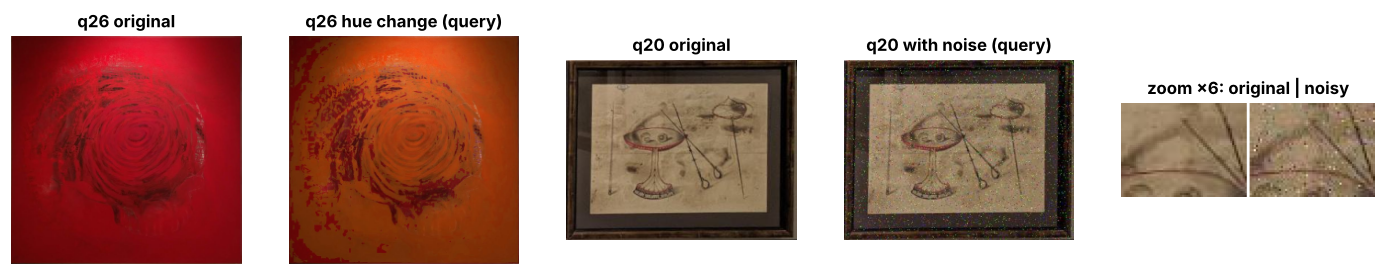

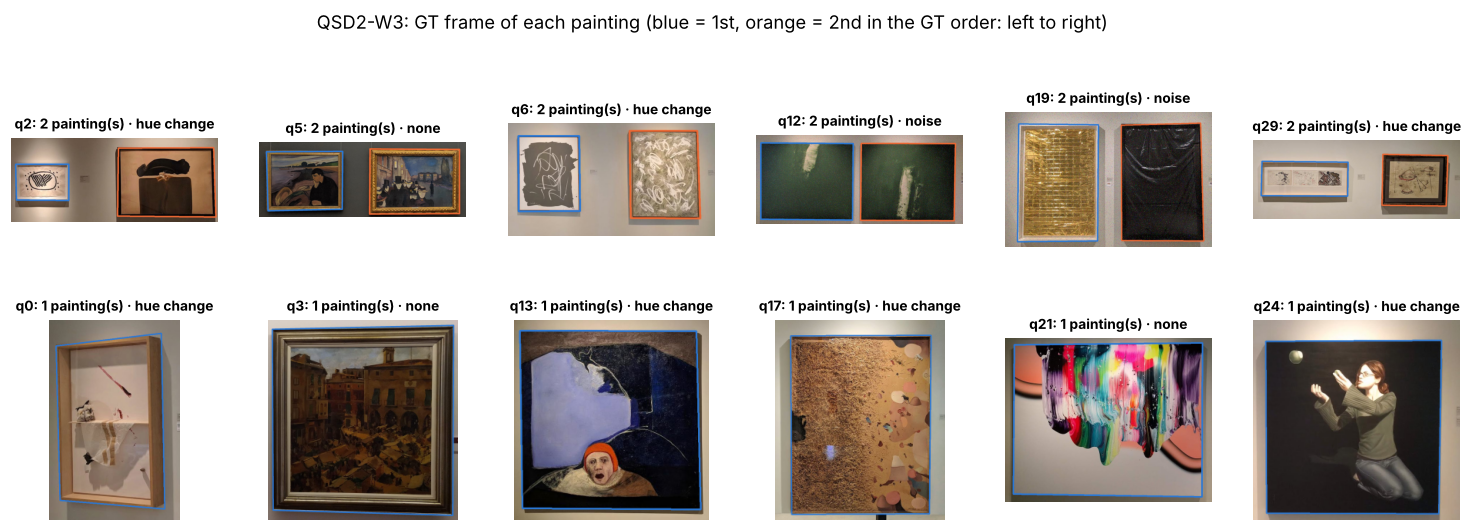

In [4]:
# Figure: what the augmentations look like (the original photo is in non_augmented/)
def thumb(img, h=230):
    s = h / img.shape[0]; return cv2.cvtColor(cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

hue_i, noise_i = 26, 20
fig, ax = plt.subplots(1, 5, figsize=(16, 3.6), gridspec_kw={'width_ratios': [1, 1, 1, 1, 1.1]})
ax[0].imshow(thumb(Q1_CLEAN[hue_i])); ax[0].set_title(f'q{hue_i} original')
ax[1].imshow(thumb(Q1_RAW[hue_i])); ax[1].set_title(f'q{hue_i} hue change (query)')
ax[2].imshow(thumb(Q1_CLEAN[noise_i])); ax[2].set_title(f'q{noise_i} original')
ax[3].imshow(thumb(Q1_RAW[noise_i])); ax[3].set_title(f'q{noise_i} with noise (query)')
y, x = 60, 100
crop = lambda im: cv2.cvtColor(cv2.resize(im[y:y + 45, x:x + 60], None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST), cv2.COLOR_BGR2RGB)
ax[4].imshow(np.hstack([crop(Q1_CLEAN[noise_i]), np.full((270, 8, 3), 255, np.uint8), crop(Q1_RAW[noise_i])]))
ax[4].set_title('zoom ×6: original | noisy')
for a in ax: a.axis('off')
savefig(fig, 'data_augmentations')

# QSD2-W3 overview with the GT polygons (frames.pkl): one or two paintings, often very close to the border
fig, ax = plt.subplots(2, 6, figsize=(17, 5.2))
for a, i in zip(ax.ravel(), [2, 5, 6, 12, 19, 29, 0, 3, 13, 17, 21, 24]):
    im = Q2_RAW[i].copy()
    for k, (ang, pts) in enumerate(Q2_FRAMES[i]):
        cv2.polylines(im, [np.int32(pts)], True, (214, 120, 42) if k == 0 else (52, 104, 235), max(3, im.shape[1] // 150))
    a.imshow(thumb(im, 260)); a.set_title(f'q{i}: {len(Q2_GT[i])} painting(s) · {AUG_NAME[Q2_AUG[i]]}', fontsize=9); a.axis('off')
fig.suptitle('QSD2-W3: GT frame of each painting (blue = 1st, orange = 2nd in the GT order: left to right)', y=1.0)
savefig(fig, 'data_qsd2_overview')

**What we see.**
* The **hue change** rotates the colours (q26: a red painting becomes orange) but keeps intensities and structure: a strong hint that
  **grey-level texture descriptors will be immune to it**, while colour histograms will not.
* The **noise** is a sprinkle of isolated pixels with random values (impulse / salt-and-pepper-like), not a soft Gaussian grain.
* In QSD2-W3 the **order** of the paintings in the GT is **left to right**, and many paintings are only 1–2 % of the image away from the
  border (much less wall than in W2). Both facts matter for Task 3.

### Validation protocol (same idea as W2)

To avoid choosing descriptors that only work on 30 queries, every descriptor is evaluated on **four** development sets
(**129 paintings** in total) and we look at all of them:

| Set | Queries | What it measures |
|---|---|---|
| **QSD1-W3** | 30 cropped queries, with noise / hue changes | the official Task 2 set |
| **QSD2-W3 (GT crop)** | 39 paintings cut from QSD2-W3 with the GT frame | other photos, other conditions, no segmentation error |
| **QSD1-W2** | 30 cropped queries of last week | robustness: different paintings |
| **QSD2-W2 (GT crop)** | 30 paintings of last week cut with the GT mask | robustness |

Metrics: **mAP@1** and **mAP@5** (the official ones) and the **MRR** (mean of 1/rank of the correct painting), which keeps
separating methods that tie in mAP@1. Remember that with 30 queries one query is 0.033: small differences are noise.

## 2. Task 1 – Noise filtering

The statement says the noise model is **unknown** and that **only some images are noisy**. So the task has three questions,
answered in order:
1. **What kind of noise is it?** (it decides the filter: theory L6)
2. **Which images are noisy?** Filtering a clean image only blurs it (and blurs its texture, which Task 2 needs).
3. **Which filter removes it best?** Measured objectively with PSNR and SSIM against `non_augmented/`.

### 2.1 What kind of noise is it?

We subtract each noisy query from its original and look at the differences.

mean_abs_diff        pct_pixels_changed_gt40        pct_pixels_changed_gt100      
                      mean    max                    mean    max                     mean   max
augmentation                                                                                   
hue change            4.68  36.40                    2.24  47.04                     0.02  0.48
noise                13.11  15.03                    3.43   4.35                     0.56  1.29
none                  0.00   0.00                    0.00   0.00                     0.00  0.00

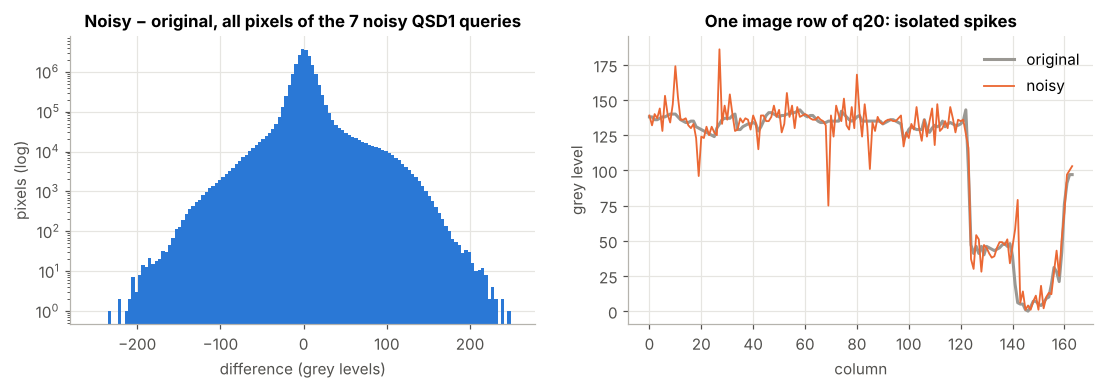

In [5]:
rows = []
for name, RAW, CLEAN, AUG in [('QSD1-W3', Q1_RAW, Q1_CLEAN, Q1_AUG), ('QSD2-W3', Q2_RAW, Q2_CLEAN, Q2_AUG)]:
    for i, (a, b) in enumerate(zip(RAW, CLEAN)):
        d = np.abs(a.astype(np.int16) - b.astype(np.int16)).max(2)
        rows.append(dict(set=name, q=i, augmentation=AUG_NAME[AUG[i]], mean_abs_diff=d.mean(),
                         pct_pixels_changed_gt40=100 * np.mean(d > 40), pct_pixels_changed_gt100=100 * np.mean(d > 100)))
noise_stats = pd.DataFrame(rows)
EXPS['T1 noise characterisation'] = noise_stats
display(noise_stats.groupby('augmentation')[['mean_abs_diff', 'pct_pixels_changed_gt40', 'pct_pixels_changed_gt100']].agg(['mean', 'max']).round(2))

# distribution of the difference (noisy - original) for the noisy queries
diffs = np.concatenate([(Q1_RAW[i].astype(np.int16) - Q1_CLEAN[i].astype(np.int16)).ravel()
                        for i in range(30) if Q1_AUG[i] == 'UnnamedImpulseNoise'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(diffs, bins=np.arange(-255, 256, 4), color=PAL['blue'], log=True)
ax[0].set_title('Noisy − original, all pixels of the 7 noisy QSD1 queries'); ax[0].set_xlabel('difference (grey levels)'); ax[0].set_ylabel('pixels (log)')
g = cv2.cvtColor(Q1_RAW[noise_i], cv2.COLOR_BGR2GRAY)[200, 150:330].astype(int)
g0 = cv2.cvtColor(Q1_CLEAN[noise_i], cv2.COLOR_BGR2GRAY)[200, 150:330].astype(int)
ax[1].plot(g0, color=PAL['grey'], lw=2, label='original'); ax[1].plot(g, color=PAL['orange'], lw=1.2, label='noisy')
ax[1].set_title(f'One image row of q{noise_i}: isolated spikes'); ax[1].set_xlabel('column'); ax[1].set_ylabel('grey level'); ax[1].legend()
savefig(fig, 't1_noise_type')

**Conclusion 2.1.** In the noisy images ~3–4 % of the pixels change by more than 40 grey levels while almost all the others
are untouched (the histogram is a narrow peak at 0 with very long tails), and a row profile shows **isolated spikes, up and down**.
This is **impulse noise** (salt-and-pepper with random values, slightly spread by the JPEG compression). The hue-changed images
change by only 1–2 grey levels on average (except q26, where the hue rotation is large), so they are not noisy.

Theory (L6, *noise reduction example*): for impulse noise, linear low-pass filters (average, Gaussian) only *spread* each spike over its
neighbours, while the **median filter** (non-linear) replaces the spike by a value of the neighbourhood and keeps the edges.
We will check this experimentally in §2.3.

### 2.2 Which images are noisy? A detector of isolated impulses

**Idea.** An impulse is a pixel that is **brighter (or darker) than all its 8 neighbours by a large margin**. Natural texture rarely
does that: edges and fine lines are shared by several neighbouring pixels. So for each image we measure

$$ r = \text{fraction of pixels } p \text{ with } \; I(p) - \max_{8\text{-nb}} I > T \;\; \text{or} \;\; \min_{8\text{-nb}} I - I(p) > T, \qquad T = 40 $$

computed with a dilation / erosion by a 3×3 **ring** (morphology, L4) on the grey image. It must be computed at the **original
resolution**: resizing to 512 px averages the impulses away (and with them the evidence). We check it on the 60 query photos
and on the 347 clean images we have (BBDD + W2 queries).

noisy images : min r = 0.0098   (16 images)
clean images : max r = 0.0025   (391 images)
accuracy of the detector with T_r = 0.005: 1.000  (false positives 0, misses 0)
same measure after resizing to 512 px: noisy min 0.0000 vs clean max 0.0035 -> not separable


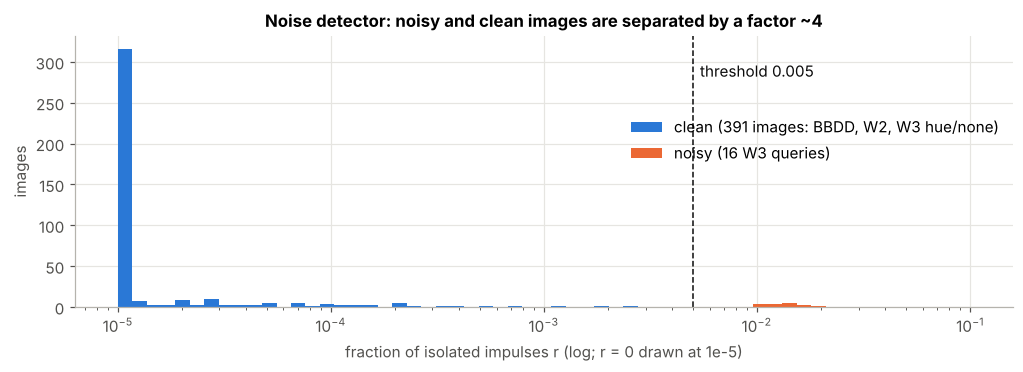

In [6]:
# impulse_ratio() is defined in the loading cell (§1), because the BBDD ratio is measured while loading it:
#   ring = 3x3 ones without the centre;  r = mean( max(I - dilate(I, ring), erode(I, ring) - I) > 40 )

det = [dict(set=s, q=i, noisy=(a == 'UnnamedImpulseNoise'), ratio=impulse_ratio(x), ratio_512=impulse_ratio(resize_max(x)))
       for s, R, A in [('QSD1-W3', Q1_RAW, Q1_AUG), ('QSD2-W3', Q2_RAW, Q2_AUG)] for i, (x, a) in enumerate(zip(R, A))]
det += [dict(set='BBDD', q=i, noisy=False, ratio=r, ratio_512=r5) for i, (r, r5) in enumerate(zip(BB_RATIO, BB_RATIO512))]
for name, d in [('QSD1-W2', QSD1W2_DIR), ('QSD2-W2', QSD2W2_DIR)]:
    if d: det += [dict(set=name, q=i, noisy=False, ratio=impulse_ratio(cv2.imread(str(p))), ratio_512=np.nan) for i, p in enumerate(jpgs(d))]
det = pd.DataFrame(det)
NOISE_T = 0.005     # threshold between the two groups (geometric middle of the gap, see the figure)
det['detected'] = det.ratio > NOISE_T
EXPS['T1 noise detector'] = det
print(f"noisy images : min r = {det[det.noisy].ratio.min():.4f}   ({det.noisy.sum()} images)")
print(f"clean images : max r = {det[~det.noisy].ratio.max():.4f}   ({(~det.noisy).sum()} images)")
print(f"accuracy of the detector with T_r = {NOISE_T}: {np.mean(det.detected == det.noisy):.3f}  "
      f"(false positives {np.sum(det.detected & ~det.noisy)}, misses {np.sum(~det.detected & det.noisy)})")
print(f"same measure after resizing to 512 px: noisy min {det[det.noisy].ratio_512.min():.4f} vs clean max {det[~det.noisy].ratio_512.max():.4f} -> not separable")

fig, ax = plt.subplots(figsize=(11, 3.2))
bins = np.logspace(-5, -1, 60)
ax.hist(det[~det.noisy].ratio.clip(1e-5), bins=bins, color=PAL['blue'], label=f'clean ({(~det.noisy).sum()} images: BBDD, W2, W3 hue/none)')
ax.hist(det[det.noisy].ratio, bins=bins, color=PAL['orange'], label=f'noisy ({det.noisy.sum()} W3 queries)')
ax.axvline(NOISE_T, color=INK, ls='--', lw=1); ax.text(NOISE_T * 1.08, ax.get_ylim()[1] * 0.85, f'threshold {NOISE_T}', color=INK)
ax.set_xscale('log'); ax.set_xlabel('fraction of isolated impulses r (log; r = 0 drawn at 1e-5)'); ax.set_ylabel('images')
ax.legend(loc='upper right', bbox_to_anchor=(1.0, 0.75))
ax.set_title('Noise detector: noisy and clean images are separated by a factor ~4')
savefig(fig, 't1_detector')

**Conclusion 2.2.** The isolated-impulse ratio separates the two groups perfectly: every noisy photo has r ≥ ~0.01 and every clean one
(including the very textured BBDD paintings) r ≤ ~0.0025. We use the threshold **0.005** (in the middle of the gap, in log scale), so
the detector has a safety margin of ×2 on each side. After resizing to 512 px the measure no longer works, which confirms that noise
must be handled at the original resolution.

### 2.3 Which filter? Linear vs non-linear, measured with PSNR and SSIM

We compare the filters of the theory (L6) plus some stronger ones: average and Gaussian (linear), median 3/5/7 and the median applied
twice (non-linear), bilateral and non-local means (edge-preserving), a morphological open–close (L4) and a *switching* median
(only replaces pixels far from the median). For each one we compute PSNR and SSIM (the image-quality metrics of the theory) against
the original photo, **on the 16 noisy images** and, to see the price of filtering when it is not needed, **on the 14 clean ones** (`None`).

In [7]:
def switching_median(img, k=5, T=20):
    med = cv2.medianBlur(img, k)
    out_ = np.abs(img.astype(np.int16) - med.astype(np.int16)).max(2) > T
    out_ = cv2.dilate(out_.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0     # JPEG spreads each impulse to its neighbours
    res = img.copy(); res[out_] = med[out_]; return res
K3 = np.ones((3, 3), np.uint8)
FILTERS = {
    'average 3×3':            lambda x: cv2.blur(x, (3, 3)),
    'average 5×5':            lambda x: cv2.blur(x, (5, 5)),
    'Gaussian σ=1':           lambda x: cv2.GaussianBlur(x, (0, 0), 1),
    'Gaussian σ=1.5':         lambda x: cv2.GaussianBlur(x, (0, 0), 1.5),
    'median 3×3':             lambda x: cv2.medianBlur(x, 3),
    'median 3×3 twice':       lambda x: cv2.medianBlur(cv2.medianBlur(x, 3), 3),
    'median 5×5':             lambda x: cv2.medianBlur(x, 5),
    'median 7×7':             lambda x: cv2.medianBlur(x, 7),
    'switching median 5×5':   lambda x: switching_median(x, 5, 20),
    'bilateral':              lambda x: cv2.bilateralFilter(x, 9, 50, 5),
    'non-local means':        lambda x: cv2.fastNlMeansDenoisingColored(x, None, 10, 10, 7, 21),
    'open–close 3×3 (morph.)': lambda x: cv2.morphologyEx(cv2.morphologyEx(x, cv2.MORPH_OPEN, K3), cv2.MORPH_CLOSE, K3),
}
LINEAR = {'average 3×3', 'average 5×5', 'Gaussian σ=1', 'Gaussian σ=1.5'}
def ssim_grey(a, b): return structural_similarity(cv2.cvtColor(a, cv2.COLOR_BGR2GRAY), cv2.cvtColor(b, cv2.COLOR_BGR2GRAY), data_range=255)

t = time.time(); rows = []
for name, RAW, CLEAN, AUG in [('QSD1-W3', Q1_RAW, Q1_CLEAN, Q1_AUG), ('QSD2-W3', Q2_RAW, Q2_CLEAN, Q2_AUG)]:
    for i in range(len(RAW)):
        if AUG[i] == 'None-MultiplyHue': continue                  # the hue change is not noise: not used here
        a, b = RAW[i], CLEAN[i]; noisy = AUG[i] == 'UnnamedImpulseNoise'
        rows.append(dict(set=name, q=i, noisy=noisy, filter='(no filter)', PSNR=cv2.PSNR(a, b) if noisy else np.inf, SSIM=ssim_grey(a, b)))
        for fname, f in FILTERS.items():
            y = f(a); rows.append(dict(set=name, q=i, noisy=noisy, filter=fname, PSNR=cv2.PSNR(y, b), SSIM=ssim_grey(y, b)))
filt = pd.DataFrame(rows); EXPS['T1 filters PSNR-SSIM'] = filt
summ = filt.groupby(['filter', 'noisy'])[['PSNR', 'SSIM']].mean().unstack('noisy')
summ.columns = [f'{m} {"noisy" if n else "clean"}' for m, n in summ.columns]
summ = summ[['PSNR noisy', 'SSIM noisy', 'PSNR clean', 'SSIM clean']].sort_values('SSIM noisy', ascending=False)
EXPS['T1 filters summary'] = summ.reset_index()
print(f'({time.time() - t:.0f}s)'); display(summ.round(3))

(197s)


,PSNR noisy,SSIM noisy,PSNR clean,SSIM clean
filter,,,,
median 3×3 twice,31.364,0.877,34.266,0.923
median 3×3,31.025,0.855,35.302,0.938
median 5×5,30.498,0.842,30.926,0.862
Gaussian σ=1.5,28.939,0.808,29.399,0.849
open–close 3×3 (morph.),27.470,0.804,30.717,0.885
median 7×7,29.600,0.801,28.625,0.800
Gaussian σ=1,29.569,0.801,32.305,0.916
average 5×5,28.390,0.778,28.570,0.819
average 3×3,29.171,0.767,32.592,0.919


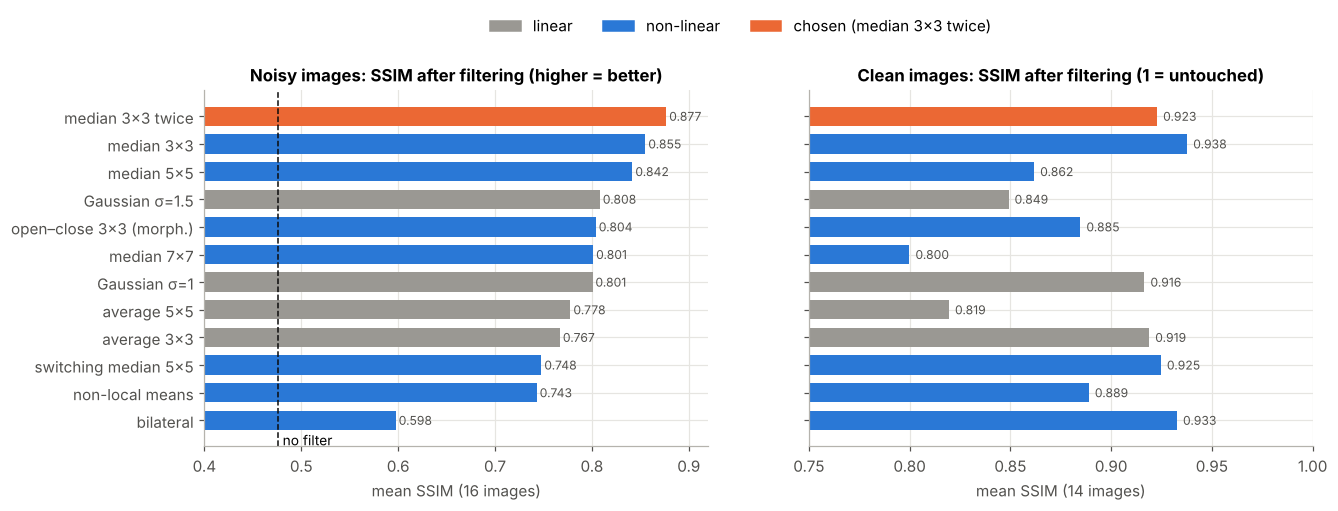

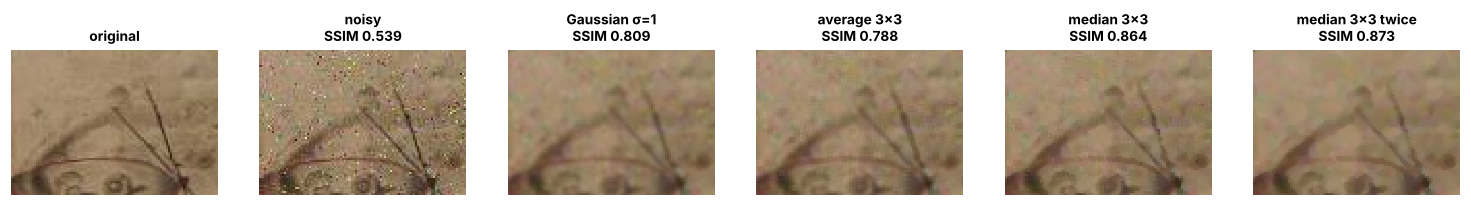

In [8]:
s = summ.drop('(no filter)')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
order = s.sort_values('SSIM noisy').index
col = [PAL['grey'] if f in LINEAR else PAL['blue'] for f in order]
col = [PAL['orange'] if f == 'median 3×3 twice' else c for f, c in zip(order, col)]
ax[0].barh(order, s.loc[order, 'SSIM noisy'], color=col, height=0.7)
ax[0].axvline(summ.loc['(no filter)', 'SSIM noisy'], color=INK, ls='--', lw=1)
ax[0].text(summ.loc['(no filter)', 'SSIM noisy'] + 0.005, -0.9, 'no filter', fontsize=9)
ax[0].set_xlim(0.4, 0.92); ax[0].set_title('Noisy images: SSIM after filtering (higher = better)'); ax[0].set_xlabel('mean SSIM (16 images)')
ax[1].barh(order, s.loc[order, 'SSIM clean'], color=col, height=0.7)
ax[1].set_xlim(0.75, 1.0); ax[1].set_title('Clean images: SSIM after filtering (1 = untouched)'); ax[1].set_xlabel('mean SSIM (14 images)')
for a, c in [(ax[0], 'SSIM noisy'), (ax[1], 'SSIM clean')]:
    for k, f in enumerate(order): a.text(s.loc[f, c] + 0.003, k, f'{s.loc[f, c]:.3f}', va='center', fontsize=8, color=INK2)
fig.legend(handles=[mpatches.Patch(color=PAL['grey'], label='linear'), mpatches.Patch(color=PAL['blue'], label='non-linear'),
                    mpatches.Patch(color=PAL['orange'], label='chosen (median 3×3 twice)')], loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.07))
savefig(fig, 't1_filters')

# visual comparison on a crop
i = noise_i; y, x, hh, ww = 40, 80, 70, 100
show = {'original': Q1_CLEAN[i], 'noisy': Q1_RAW[i], 'Gaussian σ=1': FILTERS['Gaussian σ=1'](Q1_RAW[i]),
        'average 3×3': FILTERS['average 3×3'](Q1_RAW[i]), 'median 3×3': FILTERS['median 3×3'](Q1_RAW[i]),
        'median 3×3 twice': FILTERS['median 3×3 twice'](Q1_RAW[i])}
fig, ax = plt.subplots(1, 6, figsize=(17, 2.9))
for a, (n, im) in zip(ax, show.items()):
    a.imshow(cv2.cvtColor(im[y:y + hh, x:x + ww], cv2.COLOR_BGR2RGB), interpolation='nearest'); a.axis('off')
    a.set_title(n + ('' if n == 'original' else f'\nSSIM {ssim_grey(im, Q1_CLEAN[i]):.3f}'), fontsize=9)
savefig(fig, 't1_filters_visual')

**Conclusion 2.3.**
* The **linear filters lose**: they turn every spike into a soft blob (visible in the crops) and blur the painting. This is exactly the
  example of the theory (L6): *"median filter: a non-linear filter that is very efficient for impulsive noise removal"*.
* The **median 3×3 applied twice** is the best (highest SSIM and PSNR on the noisy images): the first pass removes isolated impulses,
  the second one removes the few that JPEG had spread over 2 pixels. A single 5×5 or 7×7 median removes the noise as well but erases
  fine detail (lower SSIM). Non-local means and the bilateral filter treat the impulses as structure and keep them.
* **Filtering a clean image always costs** (SSIM drops to ~0.92–0.94 even for the median), which justifies the detector of §2.2:
  we only filter the images that the detector flags.

**Task 1 method:** `if impulse_ratio(photo) > 0.005: photo = median3×3(median3×3(photo))`, at the original resolution, before anything else
(also before the background removal, where the noise would create false "painting" speckles on the wall). Its effect on retrieval is measured in §3.6.

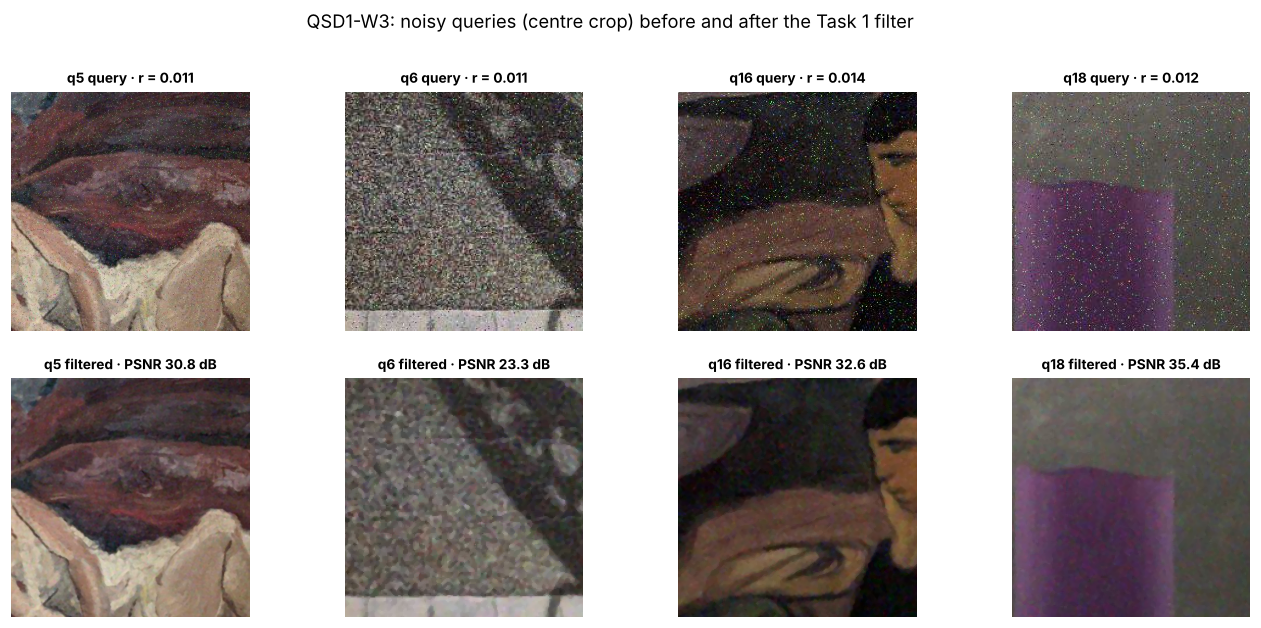

photos filtered: QSD1 7 / 30 · QSD2 9 / 30 · BBDD 0 / 287 (nothing to filter in the museum images)


In [9]:
def denoise(img):
    # Task 1 method: filter only the photos with impulse noise
    r = impulse_ratio(img)
    return (cv2.medianBlur(cv2.medianBlur(img, 3), 3) if r > NOISE_T else img), r > NOISE_T

# examples of QSD1-W3 (the statement asks to show some): detected noisy queries, before / after
ex = [i for i in range(30) if Q1_AUG[i] == 'UnnamedImpulseNoise'][:4]
fig, ax = plt.subplots(2, 4, figsize=(15, 6.2))
for k, i in enumerate(ex):
    out_, flag = denoise(Q1_RAW[i])
    hh, ww = Q1_RAW[i].shape[:2]; cy, cx, s_ = hh // 2, ww // 2, min(hh, ww) // 5
    for r_, im, lab in [(0, Q1_RAW[i], 'query'), (1, out_, 'filtered')]:
        ax[r_, k].imshow(cv2.cvtColor(im[cy - s_:cy + s_, cx - s_:cx + s_], cv2.COLOR_BGR2RGB))
        ax[r_, k].set_title(f'q{i} {lab}' + (f' · r = {impulse_ratio(Q1_RAW[i]):.3f}' if r_ == 0 else f' · PSNR {cv2.PSNR(im, Q1_CLEAN[i]):.1f} dB'), fontsize=9)
        ax[r_, k].axis('off')
fig.suptitle('QSD1-W3: noisy queries (centre crop) before and after the Task 1 filter', y=1.0)
savefig(fig, 't1_examples')
# all the images used from now on are denoised (the detector decides)
Q1 = [denoise(x)[0] for x in Q1_RAW]; Q2 = [denoise(x)[0] for x in Q2_RAW]
print('photos filtered: QSD1', sum(denoise(x)[1] for x in Q1_RAW), '/ 30 · QSD2', sum(denoise(x)[1] for x in Q2_RAW), '/ 30 · BBDD',
      sum(r > NOISE_T for r in BB_RATIO), '/ 287 (nothing to filter in the museum images)')

## 3. Task 2 – Texture descriptors

### 3.0 Why texture, and how we evaluate it

A colour histogram describes **which colours** there are (and, with blocks, where). A texture descriptor describes **how the
intensity changes** around each point: strokes, edges, grain, patterns. Two reasons make it attractive this week:
* it is computed on the **grey image**, so a **hue change does not affect it** (the hue rotation keeps the intensities);
* it describes structure that colour cannot see (e.g. two paintings with the same palette and different brush strokes).

We implement the four families asked or suggested in the statement and the theory: **LBP** (and multi-scale LBP), **block DCT**
(L6), **wavelets** (L7, multi-scale) and **HOG** (histograms of gradient orientations: derivative filters of L6 + orientation
histograms of the feature-extraction lecture). Every descriptor is computed:
* on the **denoised** image (Task 1), converted to **grey**;
* after resizing it to a **fixed square** (e.g. 256×256): the query and the museum image of the same painting then have the same
  size and the same aspect, so the k-th block of the query covers the same part of the painting as the k-th block of the BBDD image
  (the photos have arbitrary resolution and the crops arbitrary aspect);
* **per block** (spatial grid), the lesson of W2: *where* things are matters as much as *what* they are.

The development sets of §1 are built below (QSD2-W3 paintings cut with their GT frame).

In [10]:
def crop_bbox(img, pts):
    pts = np.int32(pts); x0, y0 = np.maximum(pts.min(0), 0); x1, y1 = pts.max(0)
    return img[y0:y1, x0:x1]

VAL = {'QSD1-W3': ([resize_max(x) for x in Q1], list(Q1_GT))}
VAL['QSD2-W3 (GT crop)'] = ([resize_max(crop_bbox(Q2[i], pts)) for i in range(30) for ang, pts in Q2_FRAMES[i]],
                            [g for i in range(30) for g in Q2_GT[i]])
if QSD1W2_DIR:
    VAL['QSD1-W2'] = ([resize_max(cv2.imread(str(p))) for p in jpgs(QSD1W2_DIR)], [g[0] for g in load_pkl(QSD1W2_DIR / 'gt_corresps.pkl')])
if QSD2W2_DIR:
    crops = []
    for p in jpgs(QSD2W2_DIR):
        m = cv2.imread(str(p.with_suffix('.png')), 0) > 0; x, y, w, h = cv2.boundingRect(m.astype(np.uint8))
        crops.append(resize_max(cv2.imread(str(p))[y:y + h, x:x + w]))
    VAL['QSD2-W2 (GT crop)'] = (crops, [g[0] for g in load_pkl(QSD2W2_DIR / 'gt_corresps.pkl')])
print({k: len(v[0]) for k, v in VAL.items()}, '-> total', sum(len(v[0]) for v in VAL.values()), 'paintings')

# ---------------------------------------------------------------- distances (smaller = more similar) and metrics
def dist(Q, D, kind):
    Q = np.atleast_2d(Q)
    if kind == 'chi2':      return np.stack([((q - D) ** 2 / (q + D + EPS)).sum(1) for q in Q])
    if kind == 'hellinger': return np.stack([-np.sqrt(q * D).sum(1) for q in Q])            # minus the Hellinger kernel
    if kind == 'L1':        return np.stack([np.abs(q - D).sum(1) for q in Q])
    if kind == 'L2':        return np.stack([np.linalg.norm(q - D, axis=1) for q in Q])
    if kind == 'cosine':
        Dn = D / (np.linalg.norm(D, axis=1, keepdims=True) + EPS)
        return np.stack([-(Dn @ (q / (np.linalg.norm(q) + EPS))) for q in Q])
    raise ValueError(kind)

def apk(actual, predicted, k=10):
    predicted = predicted[:k]; score, hits = 0.0, 0.0
    for i, p in enumerate(predicted):
        if p in actual and p not in predicted[:i]:
            hits += 1; score += hits / (i + 1.0)
    return score / min(len(actual), k) if actual else 0.0
def mapk(actual, predicted, k=10): return float(np.mean([apk(a, p, k) for a, p in zip(actual, predicted)]))

IDX = {int(b): i for i, b in enumerate(BB_IDS)}
def scores(dm, gt, prefix):
    order = np.argsort(dm, 1, kind='stable'); preds = [list(BB_IDS[o[:10]]) for o in order]
    ranks = np.array([1 + int(np.sum(dm[q] < dm[q, IDX[g]])) for q, g in enumerate(gt)])
    return {f'{prefix} mAP@1': mapk([[g] for g in gt], preds, 1), f'{prefix} mAP@5': mapk([[g] for g in gt], preds, 5),
            f'{prefix} MRR': float(np.mean(1 / ranks))}

def evaluate(name, fn, kind, sets=None, **params):
    # fn(img) -> 1D vector. Returns one row: per-set mAP@1, mAP@5, MRR + their means over the sets
    sets = sets or VAL; t = time.time()
    D = np.stack([fn(x) for x in BB]); row = {'descriptor': name, **params, 'distance': kind, 'dim': D.shape[1]}
    for s, (imgs, gt) in sets.items():
        row.update(scores(dist(np.stack([fn(x) for x in imgs]), D, kind), gt, s))
    row['mean mAP@1'] = np.mean([row[f'{s} mAP@1'] for s in sets]); row['mean MRR'] = np.mean([row[f'{s} MRR'] for s in sets])
    row['time (s)'] = time.time() - t
    return row

def grey_square(img, size, margin=0.0):
    if margin:
        h, w = img.shape[:2]; img = img[int(margin * h):h - int(margin * h), int(margin * w):w - int(margin * w)]
    return cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (size, size), interpolation=cv2.INTER_AREA)

def grid_hist(codes, nbins, grid):
    # one normalised histogram per block of a grid x grid partition, concatenated (sums to 1)
    h, w = codes.shape; ys, xs = np.linspace(0, h, grid + 1).astype(int), np.linspace(0, w, grid + 1).astype(int)
    out = [np.bincount(codes[ys[i]:ys[i + 1], xs[j]:xs[j + 1]].ravel(), minlength=nbins).astype(np.float32)
           for i in range(grid) for j in range(grid)]
    return np.concatenate([o / (o.sum() + EPS) for o in out]) / grid ** 2

def show_table(df, cols=None, n=10, sort='mean MRR'):
    cols = cols or [c for c in df.columns if not c.endswith('MRR') or c == 'mean MRR']
    display(df.sort_values(sort, ascending=False)[cols].head(n).round(3).reset_index(drop=True))

{'QSD1-W3': 30, 'QSD2-W3 (GT crop)': 39, 'QSD1-W2': 30, 'QSD2-W2 (GT crop)': 30} -> total 129 paintings


### 3.1 LBP – Local Binary Patterns

**How it works** (statement, slide 10). For every pixel, compare it with its P neighbours on a circle of radius R (bilinear
interpolation for the points that do not fall on a pixel): neighbour ≥ centre → 1, otherwise 0. The P bits form a code that
describes the local pattern (flat, edge, corner, line end…). The descriptor is the **histogram of codes per block**.
* It only depends on the **sign** of the differences → invariant to any monotonic change of brightness/contrast.
* **Uniform** LBP: codes with at most 2 transitions 0↔1 (edges, corners, spots) get their own bin and all the others share one:
  P + 2 bins instead of 2^P. With small blocks this keeps the histograms dense.
* **Multi-scale** LBP: concatenate LBP at several radii, so it sees patterns of several sizes.

**What we test:** the radius and the number of neighbours (P, R), the number of blocks, uniform vs. all 256 codes, multi-scale, and the distance.

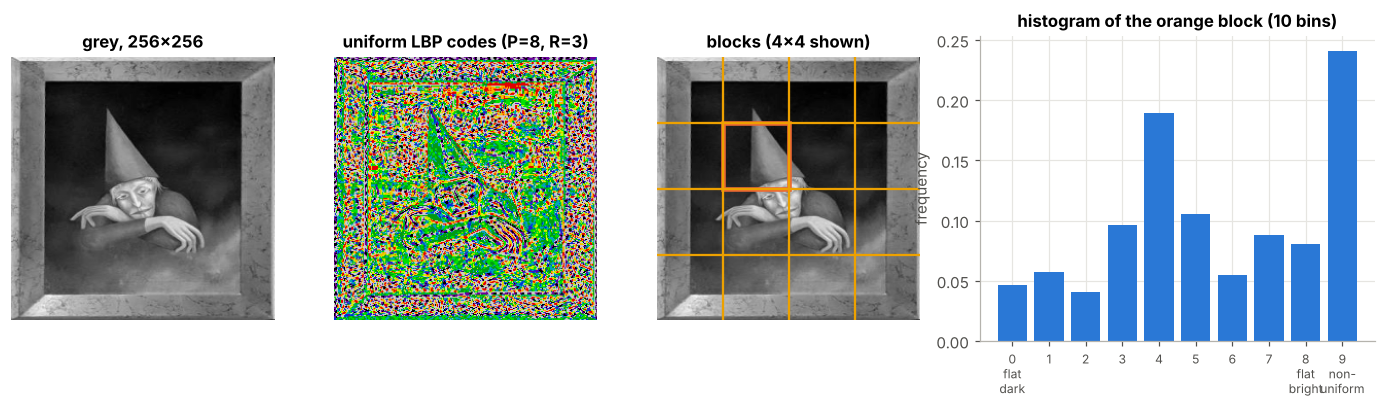

In [11]:
def lbp_map(img, P, R, size=256, method='uniform'):
    return local_binary_pattern(grey_square(img, size), P, R, method=method).astype(np.int64)
def lbp_nbins(P, method='uniform'): return P + 2 if method == 'uniform' else 2 ** P

def desc_lbp(img, scales=((8, 3),), size=256, grid=16, method='uniform'):
    # (multi-scale) uniform LBP: block histograms of each scale, concatenated with equal weight
    return np.concatenate([grid_hist(lbp_map(img, P, R, size, method), lbp_nbins(P, method), grid) / len(scales) for P, R in scales])

# visualisation
x = VAL['QSD1-W3'][0][4]
codes = lbp_map(x, 8, 3)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), gridspec_kw={'width_ratios': [1, 1, 1, 1.5]})
ax[0].imshow(grey_square(x, 256), cmap='gray'); ax[0].set_title('grey, 256×256')
ax[1].imshow(codes, cmap='nipy_spectral'); ax[1].set_title('uniform LBP codes (P=8, R=3)')
ax[2].imshow(grey_square(x, 256), cmap='gray')
for k in range(1, 4): ax[2].axhline(k * 64, color=PAL['yellow']); ax[2].axvline(k * 64, color=PAL['yellow'])
ax[2].add_patch(mpatches.Rectangle((64, 64), 64, 64, fill=False, ec=PAL['orange'], lw=3)); ax[2].set_title('blocks (4×4 shown)')
hb = np.bincount(codes[64:128, 64:128].ravel(), minlength=10)
ax[3].bar(range(10), hb / hb.sum(), color=PAL['blue']); ax[3].set_xticks(range(10))
ax[3].set_xticklabels(['0\nflat\ndark'] + [str(i) for i in range(1, 8)] + ['8\nflat\nbright', '9\nnon-\nuniform'], fontsize=8)
ax[3].set_title('histogram of the orange block (10 bins)'); ax[3].set_ylabel('frequency')
for a in ax[:3]: a.axis('off')
savefig(fig, 't2_lbp_explained')

In [12]:
t = time.time(); rows = []
LBPC = {}           # cache of code maps: (P, R, method) -> {'BBDD': [...], set: [...]}
def lbp_cached(P, R, method):
    if (P, R, method) not in LBPC:
        LBPC[(P, R, method)] = {'BBDD': [lbp_map(x, P, R, method=method) for x in BB],
                                **{s: [lbp_map(x, P, R, method=method) for x in v[0]] for s, v in VAL.items()}}
    return LBPC[(P, R, method)]
def eval_lbp(scales, grid, kind='chi2', method='uniform'):
    cs = [lbp_cached(P, R, method) for P, R in scales]; nb = [lbp_nbins(P, method) for P, R in scales]
    vec = lambda key, i: np.concatenate([grid_hist(c[key][i], n, grid) / len(scales) for c, n in zip(cs, nb)])
    D = np.stack([vec('BBDD', i) for i in range(len(BB))])
    row = {'descriptor': ('LBP' if len(scales) == 1 else 'multi-scale LBP') + (' (all 256 codes)' if method == 'default' else ' (uniform)'),
           'scales (P,R)': str(list(scales)), 'grid': f'{grid}×{grid}', 'distance': kind, 'dim': D.shape[1]}
    for s, (imgs, gt) in VAL.items():
        row.update(scores(dist(np.stack([vec(s, i) for i in range(len(imgs))]), D, kind), gt, s))
    row['mean mAP@1'] = np.mean([row[f'{s} mAP@1'] for s in VAL]); row['mean MRR'] = np.mean([row[f'{s} MRR'] for s in VAL])
    return row

for (P, R), grid in itertools.product([(8, 1), (8, 2), (8, 3), (8, 4), (16, 2), (16, 4)], [4, 8, 12, 16, 20]):
    rows.append(eval_lbp([(P, R)], grid))
for sc, grid in itertools.product([[(8, 1), (8, 3)], [(8, 2), (8, 4)], [(8, 2), (8, 3), (8, 4)], [(8, 1), (16, 2), (24, 3)]], [12, 16, 20]):
    rows.append(eval_lbp(sc, grid))
for (P, R), grid in itertools.product([(8, 1), (8, 2), (8, 3), (8, 4)], [4, 8, 10, 12]):          # all 2^8 = 256 codes
    rows.append(eval_lbp([(P, R)], grid, method='default'))
lbp_res = pd.DataFrame(rows)
print(f'{len(rows)} LBP configurations in {time.time() - t:.0f}s'); show_table(lbp_res)

58 LBP configurations in 274s


,descriptor,"scales (P,R)",grid,distance,dim,QSD1-W3 mAP@1,QSD1-W3 mAP@5,QSD2-W3 (GT crop) mAP@1,QSD2-W3 (GT crop) mAP@5,QSD1-W2 mAP@1,QSD1-W2 mAP@5,QSD2-W2 (GT crop) mAP@1,QSD2-W2 (GT crop) mAP@5,mean mAP@1,mean MRR
0,LBP (all 256 codes),"[(8, 2)]",12×12,chi2,36864,1.0,1.0,0.974,0.987,0.967,0.967,1.0,1.0,0.985,0.990
1,LBP (all 256 codes),"[(8, 2)]",10×10,chi2,25600,1.0,1.0,0.974,0.983,0.967,0.967,1.0,1.0,0.985,0.988
2,LBP (all 256 codes),"[(8, 3)]",12×12,chi2,36864,1.0,1.0,0.949,0.964,0.967,0.973,1.0,1.0,0.979,0.984
3,LBP (all 256 codes),"[(8, 3)]",10×10,chi2,25600,1.0,1.0,0.949,0.962,0.967,0.975,1.0,1.0,0.979,0.984
4,LBP (all 256 codes),"[(8, 4)]",12×12,chi2,36864,1.0,1.0,0.949,0.962,0.967,0.967,1.0,1.0,0.979,0.983
5,LBP (all 256 codes),"[(8, 1)]",12×12,chi2,36864,1.0,1.0,0.949,0.962,0.967,0.967,1.0,1.0,0.979,0.983
6,LBP (all 256 codes),"[(8, 4)]",10×10,chi2,25600,1.0,1.0,0.949,0.957,0.967,0.967,1.0,1.0,0.979,0.983
7,LBP (all 256 codes),"[(8, 4)]",8×8,chi2,16384,1.0,1.0,0.949,0.955,0.967,0.967,1.0,1.0,0.979,0.982
8,LBP (all 256 codes),"[(8, 1)]",10×10,chi2,25600,1.0,1.0,0.923,0.942,0.967,0.967,1.0,1.0,0.972,0.978
9,LBP (all 256 codes),"[(8, 3)]",8×8,chi2,16384,1.0,1.0,0.923,0.932,0.967,0.967,1.0,1.0,0.972,0.978


,descriptor,"scales (P,R)",grid,distance,dim,QSD1-W3 mAP@1,mean mAP@1,mean MRR
49,LBP (all 256 codes),"[(8, 2)]",12×12,chi2,36864,1.0,0.985,0.99
0,LBP (all 256 codes),"[(8, 2)]",12×12,hellinger,36864,1.0,0.992,0.993
1,LBP (all 256 codes),"[(8, 2)]",12×12,L1,36864,1.0,0.985,0.989
2,LBP (all 256 codes),"[(8, 2)]",12×12,L2,36864,1.0,0.945,0.954


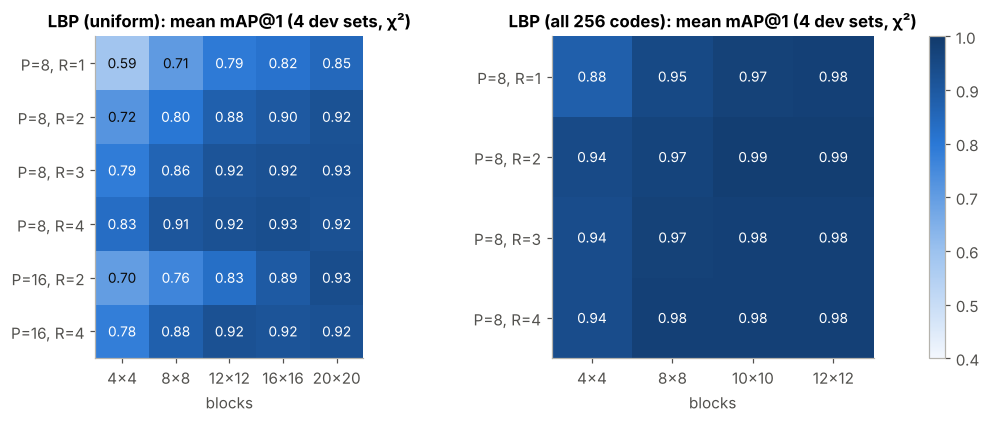

In [13]:
# distance measures on the best LBP
best = lbp_res.sort_values('mean MRR').iloc[-1]
Pb, Rb = eval(best['scales (P,R)'])[0]; gb = int(best['grid'].split('×')[0]); mb = 'default' if 'all 256' in best['descriptor'] else 'uniform'
extra = [eval_lbp([(Pb, Rb)], gb, kind, method=mb) for kind in ['hellinger', 'L1', 'L2']]
lbp_res = pd.concat([lbp_res, pd.DataFrame(extra)], ignore_index=True); EXPS['T2 LBP'] = lbp_res
display(pd.concat([best.to_frame().T, pd.DataFrame(extra)])[['descriptor', 'scales (P,R)', 'grid', 'distance', 'dim', 'QSD1-W3 mAP@1', 'mean mAP@1', 'mean MRR']].round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [5, 4]})
for a, mdesc, grids, rows_ in [(ax[0], 'LBP (uniform)', [4, 8, 12, 16, 20], [(8, 1), (8, 2), (8, 3), (8, 4), (16, 2), (16, 4)]),
                               (ax[1], 'LBP (all 256 codes)', [4, 8, 10, 12], [(8, 1), (8, 2), (8, 3), (8, 4)])]:
    hm = lbp_res[(lbp_res.descriptor == mdesc) & (lbp_res.distance == 'chi2')].pivot_table(index='scales (P,R)', columns='grid', values='mean mAP@1')
    hm = hm[[f'{g}×{g}' for g in grids]].loc[[str([pr]) for pr in rows_]]
    im = a.imshow(hm.values, cmap=SEQ, vmin=0.4, vmax=1); a.grid(False)
    a.set_xticks(range(hm.shape[1])); a.set_xticklabels(hm.columns); a.set_yticks(range(hm.shape[0]))
    a.set_yticklabels([f'P={p}, R={r}' for p, r in rows_])
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            a.text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', color='white' if hm.values[i, j] > 0.75 else INK, fontsize=9)
    a.set_xlabel('blocks'); a.set_title(f'{mdesc}: mean mAP@1 (4 dev sets, χ²)')
plt.colorbar(im, ax=ax, fraction=0.02); savefig(fig, 't2_lbp_heatmap')

**Conclusion 3.1 (LBP).**
* **Blocks are essential** (same lesson as colour in W2): a single global LBP histogram cannot tell paintings apart (mAP@1 ≈ 0.1–0.2);
  with 16×16–20×20 blocks it reaches ~0.9.
* A **larger radius** (R = 3–4 at 256 px) works better than the classic R = 1: at our resolution the brush strokes and contours are
  several pixels wide; R = 1 mostly sees JPEG grain and residual noise.
* **Uniform vs. all 256 codes – a surprise.** We expected the uniform codes to win (10 dense bins per block instead of 256 sparse ones: the
  curse of dimensionality of W2). The experiment says the opposite: with 8×8–12×12 blocks, **all 256 codes reach ≈0.98** while the best
  uniform LBP (multi-scale) stays at ≈0.95. At R = 2–4 px the paintings contain many *non-uniform* patterns (crossing strokes, grain),
  and the uniform mapping throws them all into a single bin. Fewer blocks (10×10) compensate the larger histograms.
* **Multi-scale** helps the uniform LBP (0.93 → 0.95) but not enough to reach the full-code LBP. χ², Hellinger and L1 are equivalent;
  L2 is worse, as expected for histograms.
* LBP remains the weakest family on the **QSD2 photos**: the photos taken on the wall have a different resolution, focus and lighting
  than the museum images, and the exact pattern of bits around each pixel changes with blur. **Kept: LBP P=8, R=2, all 256 codes, 10×10 blocks, χ².**

### 3.2 DCT – block Discrete Cosine Transform

**How it works** (statement slide 9 + L6). Split the grey image into blocks, apply the 2D DCT to each block, read its coefficients in
**zig-zag** order (from low to high frequency) and keep the first N. The DCT compacts the energy of natural images in the first
coefficients, so a few of them already describe the **coarse structure** of each block (its main gradients and shapes) and ignore the fine
detail and the noise (high frequencies). Two variants that we test because of the theory:
* **drop the DC** coefficient: it is just the mean brightness of the block (illumination);
* **normalise each block** to unit energy: then the descriptor encodes the *shape* of the intensity variations, not their contrast.

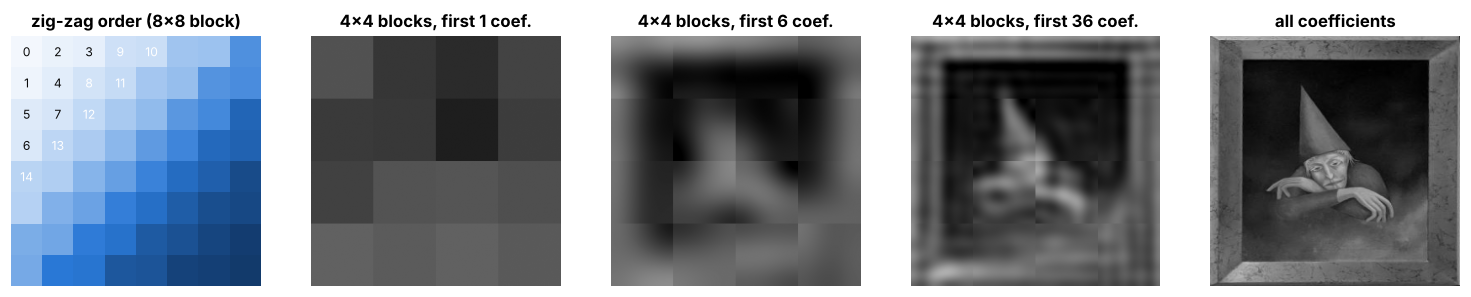

In [14]:
def zigzag(n):
    return np.array(sorted(((i, j) for i in range(n) for j in range(n)), key=lambda t: (t[0] + t[1], t[1] if (t[0] + t[1]) % 2 else t[0])))

def dct_blocks(img, size=256, n_blocks=4):
    g = grey_square(img, size).astype(np.float32); b = size // n_blocks
    return dctn(g.reshape(n_blocks, b, n_blocks, b).transpose(0, 2, 1, 3), axes=(2, 3), norm='ortho')   # (nb, nb, b, b)

def desc_dct(img, size=256, n_blocks=4, ncoef=36, drop_dc=True, block_norm=True, B=None):
    B = dct_blocks(img, size, n_blocks) if B is None else B
    zz = zigzag(B.shape[-1])[int(drop_dc):int(drop_dc) + ncoef]
    v = B[:, :, zz[:, 0], zz[:, 1]].reshape(-1, len(zz))
    if block_norm: v = v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-6)
    v = v.ravel(); return v / (np.linalg.norm(v) + EPS)

# visualisation: zig-zag order and what the first N coefficients keep
x = VAL['QSD1-W3'][0][4]; B = dct_blocks(x, 256, 4)
fig, ax = plt.subplots(1, 5, figsize=(17, 3.5))
zz8 = zigzag(8); order_img = np.zeros((8, 8))
for k, (i, j) in enumerate(zz8): order_img[i, j] = k
ax[0].imshow(order_img, cmap=SEQ); ax[0].grid(False); ax[0].set_title('zig-zag order (8×8 block)')
for k, (i, j) in enumerate(zz8[:15]): ax[0].text(j, i, k, ha='center', va='center', fontsize=8, color='white' if k > 7 else INK)
for a, N in zip(ax[1:], [1, 6, 36, 4096]):
    zz = zigzag(64)[:N]; Bk = np.zeros_like(B); Bk[:, :, zz[:, 0], zz[:, 1]] = B[:, :, zz[:, 0], zz[:, 1]]
    rec = idctn(Bk, axes=(2, 3), norm='ortho').transpose(0, 2, 1, 3).reshape(256, 256)
    a.imshow(rec, cmap='gray', vmin=0, vmax=255); a.set_title(f'4×4 blocks, first {N} coef.' if N < 4096 else 'all coefficients'); a.axis('off')
ax[0].axis('off'); savefig(fig, 't2_dct_explained')

66 DCT configurations in 326s


,descriptor,grid,block size,coefficients,drop DC,block normalisation,distance,dim,QSD1-W3 mAP@1,QSD1-W3 mAP@5,QSD2-W3 (GT crop) mAP@1,QSD2-W3 (GT crop) mAP@5,QSD1-W2 mAP@1,QSD1-W2 mAP@5,QSD2-W2 (GT crop) mAP@1,QSD2-W2 (GT crop) mAP@5,mean mAP@1,mean MRR
0,DCT,4×4,64 px,36,True,True,L2,576,1.000,1.000,0.949,0.967,0.967,0.967,0.967,0.978,0.971,0.979
1,DCT,4×4,64 px,21,True,True,L2,336,1.000,1.000,0.949,0.967,0.967,0.967,0.967,0.967,0.971,0.977
2,DCT,4×4,64 px,15,True,True,L2,240,1.000,1.000,0.949,0.962,0.967,0.967,0.967,0.967,0.971,0.976
3,DCT,4×4,64 px,10,True,True,L2,160,1.000,1.000,0.949,0.962,0.967,0.967,0.967,0.967,0.971,0.975
4,DCT,8×8,32 px,6,True,True,L2,384,0.967,0.983,0.923,0.954,0.967,0.967,0.967,0.973,0.956,0.970
5,DCT,8×8,32 px,10,True,True,L2,640,0.967,0.983,0.897,0.932,0.967,0.973,0.967,0.978,0.949,0.967
6,DCT,4×4,64 px,36,False,False,L2,576,1.000,1.000,0.897,0.910,0.967,0.967,0.967,0.967,0.958,0.963
7,DCT,8×8,32 px,15,False,False,L2,960,1.000,1.000,0.897,0.906,0.967,0.967,0.967,0.967,0.958,0.962
8,DCT,8×8,32 px,10,False,False,L2,640,1.000,1.000,0.897,0.906,0.967,0.967,0.967,0.967,0.958,0.962
9,DCT,4×4,64 px,36,True,False,L2,576,0.967,0.978,0.949,0.949,0.933,0.942,0.967,0.967,0.954,0.961


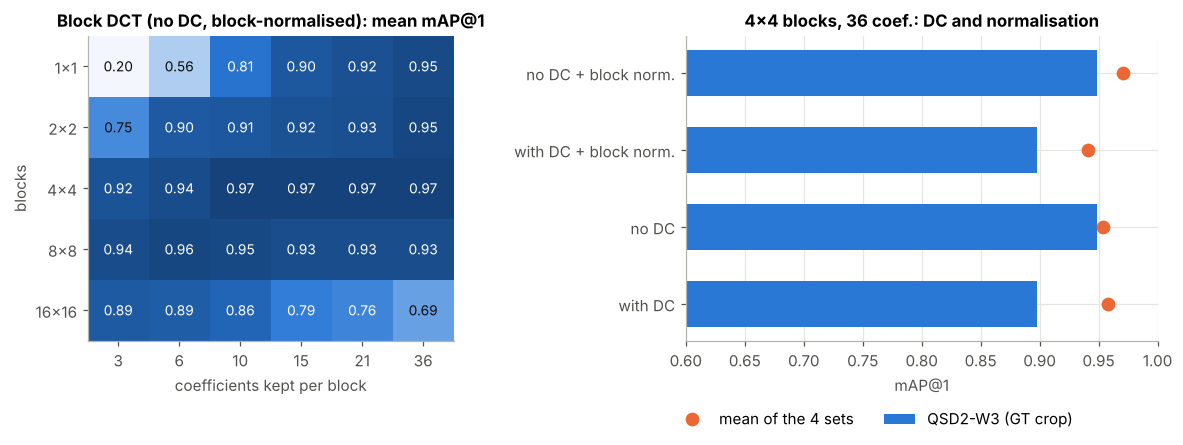

In [15]:
t = time.time(); rows = []
for n_blocks in [1, 2, 4, 8, 16]:
    cacheB = {'BBDD': [dct_blocks(x, 256, n_blocks) for x in BB], **{s: [dct_blocks(x, 256, n_blocks) for x in v[0]] for s, v in VAL.items()}}
    for ncoef, (drop_dc, bn) in itertools.product([3, 6, 10, 15, 21, 36], [(False, False), (True, False), (False, True), (True, True)]):
        if ncoef + drop_dc > (256 // n_blocks) ** 2: continue
        if (drop_dc, bn) != (True, True) and n_blocks not in (4, 8): continue      # variants only on 2 grids (they are cheap but crowd the table)
        D = np.stack([desc_dct(None, ncoef=ncoef, drop_dc=drop_dc, block_norm=bn, B=b) for b in cacheB['BBDD']])
        row = {'descriptor': 'DCT', 'grid': f'{n_blocks}×{n_blocks}', 'block size': f'{256 // n_blocks} px', 'coefficients': ncoef,
               'drop DC': drop_dc, 'block normalisation': bn, 'distance': 'L2', 'dim': D.shape[1]}
        for s, (imgs, gt) in VAL.items():
            Q = np.stack([desc_dct(None, ncoef=ncoef, drop_dc=drop_dc, block_norm=bn, B=b) for b in cacheB[s]])
            row.update(scores(dist(Q, D, 'L2'), gt, s))
        row['mean mAP@1'] = np.mean([row[f'{s} mAP@1'] for s in VAL]); row['mean MRR'] = np.mean([row[f'{s} MRR'] for s in VAL])
        rows.append(row)
dct_res = pd.DataFrame(rows); EXPS['T2 DCT'] = dct_res
print(f'{len(rows)} DCT configurations in {time.time() - t:.0f}s'); show_table(dct_res)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={'width_ratios': [1.3, 1]})
hm = dct_res[dct_res['drop DC'] & dct_res['block normalisation']].pivot_table(index='grid', columns='coefficients', values='mean mAP@1')
hm = hm.loc[[g for g in ['1×1', '2×2', '4×4', '8×8', '16×16'] if g in hm.index]]
im = ax[0].imshow(hm.values, cmap=SEQ, vmin=0.4, vmax=1); ax[0].grid(False)
ax[0].set_xticks(range(hm.shape[1])); ax[0].set_xticklabels(hm.columns); ax[0].set_yticks(range(hm.shape[0])); ax[0].set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        if not np.isnan(hm.values[i, j]): ax[0].text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', color='white' if hm.values[i, j] > 0.75 else INK, fontsize=9)
ax[0].set_xlabel('coefficients kept per block'); ax[0].set_ylabel('blocks'); ax[0].set_title('Block DCT (no DC, block-normalised): mean mAP@1')
v = dct_res[(dct_res.grid == '4×4') & (dct_res.coefficients == 36)].copy()
v['variant'] = v.apply(lambda r: ('no DC' if r['drop DC'] else 'with DC') + (' + block norm.' if r['block normalisation'] else ''), axis=1)
ax[1].barh(v['variant'], v['QSD2-W3 (GT crop) mAP@1'], color=PAL['blue'], height=0.6, label='QSD2-W3 (GT crop)')
ax[1].plot(v['mean mAP@1'], v['variant'], 'o', color=PAL['orange'], ms=8, label='mean of the 4 sets')
ax[1].set_xlim(0.6, 1.0); ax[1].set_title('4×4 blocks, 36 coef.: DC and normalisation'); ax[1].set_xlabel('mAP@1')
ax[1].legend(loc='upper center', bbox_to_anchor=(0.4, -0.18), ncol=2)
savefig(fig, 't2_dct_results')

**Conclusion 3.2 (DCT).**
* The reconstructions show what the descriptor sees: with 6–36 coefficients per block we keep the **composition** of the painting (a
  blurred version), without fine detail and without noise. That is exactly what survives between the museum image and a photo of it.
* **Removing the DC** is what makes block DCT work on the photos: on QSD2-W3 it goes from 0.90 to 0.95 (the DC is the brightness of the block,
  which changes with the museum lighting). **Normalising each block** to unit energy adds contrast invariance and raises the mean of the
  four sets from 0.955 to 0.971. With both, block DCT reaches **mAP@1 = 1.00 on QSD1-W3**.
* The result is flat from 6 to 36 coefficients and from 2×2 to 8×8 blocks with ~4×4 the best: a robust choice, not a lucky one.

### 3.3 Wavelets – multi-scale texture energy (L7)

**How it works.** The 2D wavelet transform (L7, multi-scale processing) splits the image, level by level, into a low-pass
**approximation** and three **detail** sub-bands (horizontal, vertical and diagonal edges) at each scale. With Haar wavelets a level is
just "average and difference of neighbouring pixels". Our descriptor: for every sub-band and every block of a grid, the **mean absolute
value** and the **standard deviation** of the coefficients (how much texture of that orientation and that scale there is there),
plus the (standardised) approximation as a coarse layout. The vector is L2-normalised.

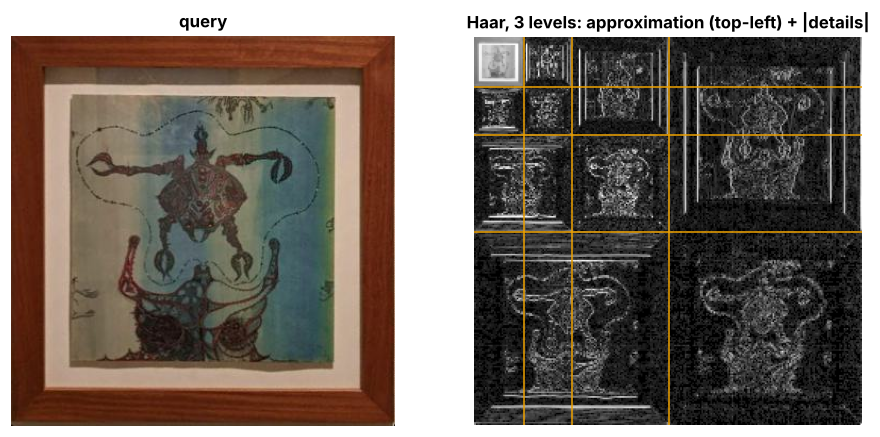

20 wavelet configurations in 165s


,descriptor,wavelet,levels,grid,approximation,stats,distance,dim,QSD1-W3 mAP@1,QSD1-W3 mAP@5,QSD2-W3 (GT crop) mAP@1,QSD2-W3 (GT crop) mAP@5,QSD1-W2 mAP@1,QSD1-W2 mAP@5,QSD2-W2 (GT crop) mAP@1,QSD2-W2 (GT crop) mAP@5,mean mAP@1,mean MRR,time (s)
0,wavelet,haar,3,8×8,True,mean|c| + std,L1,1280,1.0,1.0,0.974,0.974,1.000,1.000,0.967,0.975,0.985,0.988,10.780
1,wavelet,haar,3,12×12,True,mean|c| + std,L1,2880,1.0,1.0,0.974,0.974,1.000,1.000,0.967,0.967,0.985,0.986,21.353
2,wavelet,haar,4,8×8,True,mean|c| + std,L1,1664,1.0,1.0,0.974,0.974,1.000,1.000,0.967,0.967,0.985,0.986,13.183
3,wavelet,haar,4,12×12,True,mean|c| + std,L1,3744,1.0,1.0,0.974,0.974,1.000,1.000,0.967,0.967,0.985,0.986,26.640
4,wavelet,haar,2,8×8,True,mean|c| + std,L1,896,1.0,1.0,0.974,0.981,0.967,0.978,0.967,0.978,0.977,0.984,7.666
5,wavelet,haar,2,12×12,True,mean|c| + std,L1,2016,1.0,1.0,0.974,0.974,0.967,0.983,0.967,0.975,0.977,0.984,15.315
6,wavelet,haar,1,8×8,True,mean|c| + std,L1,512,1.0,1.0,0.949,0.962,0.967,0.967,1.000,1.000,0.979,0.984,4.766
7,wavelet,haar,3,8×8,True,mean|c|,L1,640,1.0,1.0,0.974,0.974,0.967,0.978,0.967,0.967,0.977,0.981,4.300
8,wavelet,haar,1,12×12,True,mean|c| + std,L1,1152,1.0,1.0,0.974,0.974,0.967,0.967,0.967,0.967,0.977,0.981,8.861
9,wavelet,haar,3,8×8,True,mean|c| + std,L2,1280,1.0,1.0,0.949,0.949,0.967,0.973,0.967,0.967,0.971,0.973,10.542


In [16]:
def desc_wavelet(img, size=256, level=3, grid=8, wave='haar', approx=True, stats=('mav', 'std')):
    g = grey_square(img, size).astype(np.float32) / 255
    co = pywt.wavedec2(g, wave, level=level)
    bands = [b for lv in co[1:] for b in lv]
    if approx: a = co[0]; bands = [(a - a.mean()) / (a.std() + 1e-6)] + bands
    out = []
    for b in bands:
        h, w = b.shape; n = min(grid, h); ys, xs = np.linspace(0, h, n + 1).astype(int), np.linspace(0, w, n + 1).astype(int)
        for i in range(n):
            for j in range(n):
                bb = b[ys[i]:ys[i + 1], xs[j]:xs[j + 1]]
                if 'mav' in stats: out.append(np.mean(np.abs(bb)))
                if 'std' in stats: out.append(np.std(bb))
    v = np.array(out, np.float32); return v / (np.linalg.norm(v) + EPS)

# visualisation of a 3-level Haar decomposition
x = VAL['QSD1-W3'][0][12]
co = pywt.wavedec2(grey_square(x, 256).astype(np.float32) / 255, 'haar', level=3)
arr, _ = pywt.coeffs_to_array([co[0] / np.abs(co[0]).max()] + [tuple(np.abs(d) / (np.abs(d).max() + 1e-6) for d in lv) for lv in co[1:]])
fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
ax[0].imshow(cv2.cvtColor(x, cv2.COLOR_BGR2RGB)); ax[0].set_title('query'); ax[0].axis('off')
ax[1].imshow(np.sqrt(arr), cmap='gray'); ax[1].set_title('Haar, 3 levels: approximation (top-left) + |details|'); ax[1].axis('off')
for k in [32, 64, 128]: ax[1].axhline(k, color=PAL['yellow'], lw=1); ax[1].axvline(k, color=PAL['yellow'], lw=1)
savefig(fig, 't2_wavelet_explained')

t = time.time(); rows = []
for level, grid in itertools.product([1, 2, 3, 4], [2, 4, 8, 12]):
    rows.append(evaluate('wavelet', lambda x: desc_wavelet(x, 256, level, grid), 'L1', wavelet='haar', levels=level, grid=f'{grid}×{grid}', approximation=True, stats='mean|c| + std'))
for kw in [dict(approx=False), dict(stats=('mav',)), dict(wave='db2')]:
    rows.append(evaluate('wavelet', lambda x: desc_wavelet(x, 256, 3, 8, **kw), 'L1', wavelet=kw.get('wave', 'haar'), levels=3, grid='8×8',
                         approximation=kw.get('approx', True), stats='mean|c|' if 'stats' in kw else 'mean|c| + std'))
rows.append(evaluate('wavelet', lambda x: desc_wavelet(x, 256, 3, 8), 'L2', wavelet='haar', levels=3, grid='8×8', approximation=True, stats='mean|c| + std'))
wav_res = pd.DataFrame(rows); EXPS['T2 wavelet'] = wav_res
print(f'{len(rows)} wavelet configurations in {time.time() - t:.0f}s'); show_table(wav_res, n=12)

**Conclusion 3.3 (wavelets).** The wavelet descriptor is the most accurate *single* family on the four sets (mean mAP@1 ≈ 0.98–0.99,
**1.00 on QSD1-W3**). 3 levels and an 8×8 grid lie on a plateau (2–4 levels and 8–12 blocks give the same). The standardised approximation
helps (it adds the coarse layout to the texture energies), and the L1 distance is slightly better than L2. Haar and Daubechies-2 are
equivalent. **Kept: Haar, 3 levels, 8×8 blocks, mean|c| + std, L1.**

### 3.4 HOG – histograms of oriented gradients

**How it works.** Compute the image gradient (derivative filters, L6); in each cell of `c×c` pixels build a histogram of the gradient
**orientations** weighted by their magnitude; normalise the histograms in overlapping blocks of `b×b` cells (robust to local contrast).
It describes **the shapes and edges** of each region of the painting and, like LBP, it ignores the hue. We test the cell size, the block
size, the number of orientations and the image size.

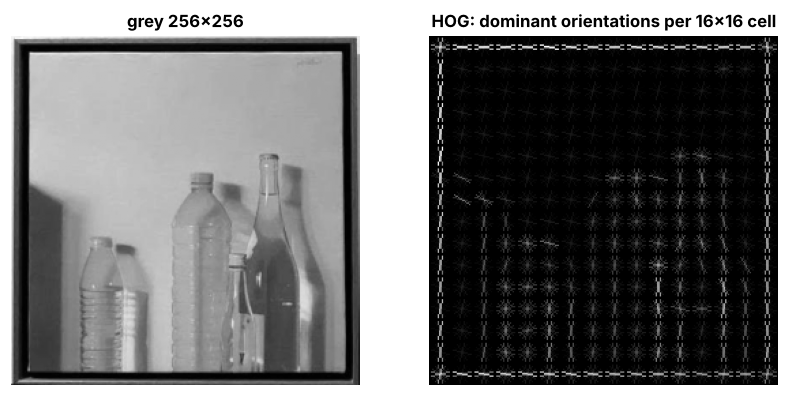

32 HOG configurations in 102s · 12 of them are perfect on the 4 sets


,descriptor,size,cell,block (cells),orientations,distance,dim,QSD1-W3 mAP@1,QSD1-W3 mAP@5,QSD2-W3 (GT crop) mAP@1,QSD2-W3 (GT crop) mAP@5,QSD1-W2 mAP@1,QSD1-W2 mAP@5,QSD2-W2 (GT crop) mAP@1,QSD2-W2 (GT crop) mAP@5,mean mAP@1,mean MRR,time (s)
0,HOG,128×128,8×8 px,3×3,12,L2,21168,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,5.312
1,HOG,128×128,8×8 px,3×3,8,L2,14112,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.343
2,HOG,128×128,16×16 px,2×2,12,L2,2352,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.842
3,HOG,128×128,16×16 px,2×2,8,L2,1568,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.572
4,HOG,128×128,16×16 px,3×3,12,L2,3888,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.759
5,HOG,128×128,16×16 px,3×3,8,L2,2592,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.545
6,HOG,256×256,16×16 px,3×3,12,L2,21168,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.835
7,HOG,256×256,16×16 px,3×3,8,L2,14112,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,6.170
8,HOG,128×128,16×16 px,2×2,8,cosine,1568,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.426
9,HOG,128×128,16×16 px,2×2,8,L1,1568,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.528


In [17]:
def desc_hog(img, size=128, cell=16, block=2, orientations=8):
    v = hog(grey_square(img, size), orientations=orientations, pixels_per_cell=(cell, cell), cells_per_block=(block, block),
            feature_vector=True).astype(np.float32)
    return v / (np.linalg.norm(v) + EPS)

x = VAL['QSD1-W3'][0][13]
_, hv = hog(grey_square(x, 256), orientations=8, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
ax[0].imshow(grey_square(x, 256), cmap='gray'); ax[0].set_title('grey 256×256'); ax[0].axis('off')
ax[1].imshow(hv ** 0.6, cmap='gray'); ax[1].set_title('HOG: dominant orientations per 16×16 cell'); ax[1].axis('off')
savefig(fig, 't2_hog_explained')

t = time.time(); rows = []
for size, cell, block, ori in itertools.product([128, 256], [8, 16, 32], [1, 2, 3], [8, 12]):
    if size // cell < block or (size == 256 and cell == 8): continue
    rows.append(evaluate('HOG', lambda x: desc_hog(x, size, cell, block, ori), 'L2', size=f'{size}×{size}', cell=f'{cell}×{cell} px',
                         **{'block (cells)': f'{block}×{block}'}, orientations=ori))
for kind in ['L1', 'cosine']:
    rows.append(evaluate('HOG', lambda x: desc_hog(x, 128, 16, 2, 8), kind, size='128×128', cell='16×16 px', **{'block (cells)': '2×2'}, orientations=8))
hog_res = pd.DataFrame(rows); EXPS['T2 HOG'] = hog_res
print(f'{len(rows)} HOG configurations in {time.time() - t:.0f}s · {np.sum(hog_res["mean mAP@1"] == 1)} of them are perfect on the 4 sets')
show_table(hog_res, n=12)

**Conclusion 3.4 (HOG).** HOG is the strongest texture descriptor: many configurations retrieve **all 129 development paintings at
rank 1** (mean mAP@1 = 1.000). It needs cells of ~1/8 of the image (16 px at 128×128 or 32 px at 256×256) and block normalisation
(blocks of 2–3 cells): it is precisely this local contrast normalisation that makes it robust to the different lighting of the
photos. Too small cells (8 px) describe noise and fine detail that change between photo and museum image. **Kept: 128×128, 16×16 cells,
2×2 blocks, 8 orientations, L2** (perfect, compact: 1 568 values, and in the middle of the plateau).

### 3.5 Comparison: texture vs. colour, and the effect of the noise filter

The best configuration of each family is now compared with our **W2 colour descriptor** (3D YCrCb pyramid, the best QST2 retrieval of the
class in W2). We also look at each **augmentation type** of QSD1-W3 separately and at what happens **without the Task 1 filter**.

In [18]:
# W2 colour descriptor (method1 of week 2), unchanged
MARGIN, BINS, LEVELS, LWEIGHTS = 0.05, (6, 12, 12), (1, 2, 4, 8), (1, 2, 4, 8)
def prepare_color(img):
    h, w = img.shape[:2]; f = img[int(MARGIN * h):h - int(MARGIN * h), int(MARGIN * w):w - int(MARGIN * w)].astype(np.float32)
    f = np.clip(f * (128 / (f.reshape(-1, 3).mean(0) + EPS)), 0, 255).astype(np.uint8)          # light: each channel to mean 128
    return cv2.cvtColor(f, cv2.COLOR_BGR2YCrCb)
P_ = np.concatenate([prepare_color(x).reshape(-1, 3) for x in BB])
P_ = P_[np.random.default_rng(0).choice(len(P_), 300_000, replace=False)].astype(np.float64)
EDGES = []
for c, n in enumerate(BINS):
    lo, hi = np.percentile(P_[:, c], [0.5, 99.5]); e = np.linspace(lo, hi, n + 1); e[0], e[-1] = -1, 256; EDGES.append(e)
LUTS = [np.clip(np.searchsorted(e[1:-1], np.arange(256), side='right'), 0, len(e) - 2) for e in EDGES]
def desc_color(img):
    x = prepare_color(img); idx = LUTS[0][x[..., 0]] * BINS[1] * BINS[2] + LUTS[1][x[..., 1]] * BINS[2] + LUTS[2][x[..., 2]]
    h, w = idx.shape; wts = np.asarray(LWEIGHTS, float) / np.sum(LWEIGHTS); out = []
    for n, wl in zip(LEVELS, wts):
        ys, xs = np.linspace(0, h, n + 1).astype(int), np.linspace(0, w, n + 1).astype(int)
        for i in range(n):
            for j in range(n):
                hb = np.bincount(idx[ys[i]:ys[i + 1], xs[j]:xs[j + 1]].ravel(), minlength=int(np.prod(BINS))).astype(np.float32)
                out.append(wl * hb / (hb.sum() + EPS) / (n * n))
    return np.concatenate(out)

# the final configuration of each family (chosen above, always in the plateau)
DESCRIPTORS = {
    'LBP':               (lambda x: desc_lbp(x, ((8, 2),), 256, 10, method='default'), 'chi2'),
    'DCT':               (lambda x: desc_dct(x, 256, 4, 36), 'L2'),
    'Wavelet':           (lambda x: desc_wavelet(x, 256, 3, 8), 'L1'),
    'HOG':               (lambda x: desc_hog(x, 128, 16, 2, 8), 'L2'),
    'Colour (W2)':       (desc_color, 'hellinger'),
}
t = time.time()
DB = {k: np.stack([f(x) for x in BB]) for k, (f, _) in DESCRIPTORS.items()}           # museum descriptors, computed once
_DM_CACHE = {}
def dm_of(name, imgs):
    # distance matrix (queries x 287) of one descriptor; cached per image object, so experiments that reuse images are fast
    f, kind = DESCRIPTORS[name]; rows_ = []
    for x in imgs:
        key = (name, id(x))
        if key not in _DM_CACHE: _DM_CACHE[key] = (x, dist(f(x)[None], DB[name], kind)[0])   # keep x alive so its id stays unique
        rows_.append(_DM_CACHE[key][1])
    return np.stack(rows_)
DMS = {(n, s): dm_of(n, v[0]) for n in DESCRIPTORS for s, v in VAL.items()}            # distance matrices on the dev sets
DMS.update({(n, 'QSD1-W3 (no filter)'): dm_of(n, [resize_max(x) for x in Q1_RAW]) for n in DESCRIPTORS})
DMS.update({(n, 'QSD1-W3 (original, no augmentation)'): dm_of(n, [resize_max(x) for x in Q1_CLEAN]) for n in DESCRIPTORS})
print(f'({time.time() - t:.0f}s)')
rows = []
for n in DESCRIPTORS:
    r = {'descriptor': n, 'family': 'colour' if 'Colour' in n else 'texture', 'dim': DB[n].shape[1]}
    for s, (imgs, gt) in VAL.items(): r.update(scores(DMS[(n, s)], gt, s))
    r['mean mAP@1'] = np.mean([r[f'{s} mAP@1'] for s in VAL])
    r.update(scores(DMS[(n, 'QSD1-W3 (no filter)')], Q1_GT, 'QSD1-W3 no filter'))
    rows.append(r)
best_desc = pd.DataFrame(rows); EXPS['T2 best descriptors'] = best_desc
display(best_desc[['descriptor', 'family', 'dim', 'QSD1-W3 mAP@1', 'QSD1-W3 mAP@5', 'QSD1-W3 no filter mAP@1'] +
                  [f'{s} mAP@1' for s in list(VAL)[1:]] + ['mean mAP@1']].round(3))

(75s)


,descriptor,family,dim,QSD1-W3 mAP@1,QSD1-W3 mAP@5,QSD1-W3 no filter mAP@1,QSD2-W3 (GT crop) mAP@1,QSD1-W2 mAP@1,QSD2-W2 (GT crop) mAP@1,mean mAP@1
0,LBP,texture,25600,1.000,1.000,0.900,0.974,0.967,1.000,0.985
1,DCT,texture,576,1.000,1.000,1.000,0.949,0.967,0.967,0.971
2,Wavelet,texture,1280,1.000,1.000,1.000,0.974,1.000,0.967,0.985
3,HOG,texture,1568,1.000,1.000,0.967,1.000,1.000,1.000,1.000
4,Colour (W2),colour,73440,0.967,0.967,0.967,0.897,0.967,1.000,0.958


input         no filter            original photo            with filter           
augmentation hue change noise none     hue change noise none  hue change noise none
descriptor                                                                         
Colour (W2)        0.93  1.00  1.0            1.0   1.0  1.0        0.93   1.0  1.0
DCT                1.00  1.00  1.0            1.0   1.0  1.0        1.00   1.0  1.0
HOG                1.00  0.86  1.0            1.0   1.0  1.0        1.00   1.0  1.0
LBP                1.00  0.57  1.0            1.0   1.0  1.0        1.00   1.0  1.0
Wavelet            1.00  1.00  1.0            1.0   1.0  1.0        1.00   1.0  1.0

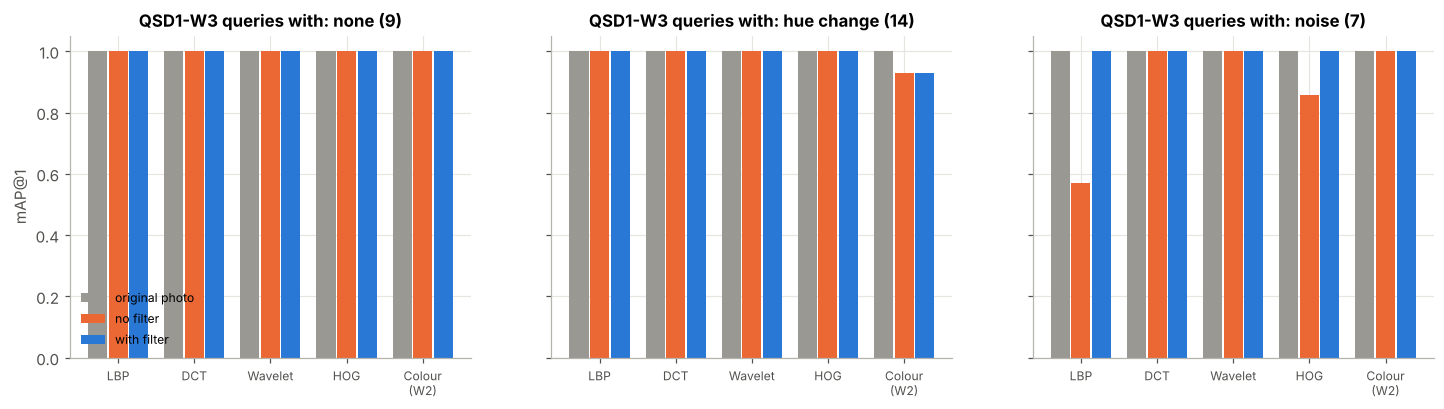

In [19]:
# per augmentation type on QSD1-W3: rank of the correct painting, with and without the Task 1 filter
rank = lambda dm, gt: np.array([1 + int(np.sum(dm[q] < dm[q, IDX[g]])) for q, g in enumerate(gt)])
aug = pd.Series(Q1_AUG).map(AUG_NAME)
rows = []
for n in DESCRIPTORS:
    for cond, key in [('with filter', 'QSD1-W3'), ('no filter', 'QSD1-W3 (no filter)'), ('original photo', 'QSD1-W3 (original, no augmentation)')]:
        r = rank(DMS[(n, key)], Q1_GT)
        for a in ['none', 'hue change', 'noise']:
            rows.append(dict(descriptor=n, input=cond, augmentation=a, queries=int(np.sum(aug == a)),
                             **{'mAP@1': np.mean(r[aug == a] == 1), 'mean rank of correct': np.mean(r[aug == a])}))
per_aug = pd.DataFrame(rows); EXPS['T2 per augmentation'] = per_aug
display(per_aug.pivot_table(index='descriptor', columns=['input', 'augmentation'], values='mAP@1').round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
names = list(DESCRIPTORS)
for a, augm in zip(ax, ['none', 'hue change', 'noise']):
    for k, (cond, c) in enumerate([('original photo', PAL['grey']), ('no filter', PAL['orange']), ('with filter', PAL['blue'])]):
        v = [per_aug[(per_aug.descriptor == n) & (per_aug.input == cond) & (per_aug.augmentation == augm)]['mAP@1'].iloc[0] for n in names]
        a.bar(np.arange(len(names)) + (k - 1) * 0.27, v, 0.25, color=c, label=cond)
    a.set_xticks(range(len(names))); a.set_xticklabels([n.replace(' (', '\n(') for n in names], fontsize=8)
    a.set_title(f'QSD1-W3 queries with: {augm} ({int(np.sum(aug == augm))})'); a.set_ylim(0, 1.05)
ax[0].set_ylabel('mAP@1'); ax[0].legend(loc='lower left', fontsize=8)
savefig(fig, 't2_per_augmentation')

**Conclusion 3.5 – answer to Task 2.**
* Using **only texture descriptors**, QSD1-W3 is solved: **HOG, wavelet and DCT give mAP@1 = mAP@5 = 1.000** (LBP 0.97–1.00). The
  most robust across the four sets are **HOG** (1.000 on all 129 paintings) and **wavelets** (≈0.98).
* The **hue change** hurts only the **colour** descriptor (it is the only one that fails a hue-changed query, q26: the red painting
  that became orange). All texture descriptors are computed on grey levels and are immune to it.
* The **noise** hurts the descriptors built on **fine gradients**: without the Task 1 filter LBP drops to 0.57 and HOG to 0.86 on the noisy
  queries (each impulse is a strong local gradient / a wrong bit pattern). **With the filter both are back to 1.00.** DCT, wavelets and
  colour summarise larger areas and do not notice the impulses. Task 1 is therefore a prerequisite for the best texture descriptors.

| Task 2 table (QSD1-W3) | mAP@1 | mAP@5 |
|---|---|---|
| W2 colour descriptor (best of last week) | 0.967 | 0.967 |
| **Best texture-only descriptor (HOG; wavelets and DCT tie)** | **1.000** | **1.000** |

So texture alone is enough for QSD1. For the photos of QSD2 we will need more than one descriptor (§5): the crops made with *our*
masks are less clean than the GT crops, and each family fails in different queries.

## 4. Task 3 – Detect all the paintings (max. 2) and remove the background

### 4.1 Where we start from

The class results of W2 tell us which masks generalise best: on QST2 the best F1 was **0.98 (Teams 2, 8 and 3)**; ours was 0.96.
Team 8 published their code, so we start from **their wall model** and compare it with our W2 method on the new data:

* **Our W2 method:** Gaussian model of the wall colour (Lab) from a 15-px border strip → Mahalanobis distance → Otsu → morphology →
  *largest* component.
* **Team 8 W2 method:** the wall **chroma (a, b) is modelled as a quadratic function of its lightness L**, fitted with robust re-weighting
  on a 4 % border strip. Spotlights and shadows change the lightness of the wall but not its colour, so for every pixel the model predicts
  *the colour the wall would have at that brightness*, and the Mahalanobis distance to that prediction decides (≤ 5.5 → wall-like).
  Wall = wall-like pixels **connected to the border**; very dark pixels are never wall. Then closing, row/column filling, hole filling,
  and removal of rows/columns with < 50 % painting.

This week there is **no "only colour" restriction** in Task 3, but colour is still the main cue; we will use edges only where colour
cannot work (§4.4).

In [20]:
def border_strip(h, w, ratio):
    bh, bw = max(2, int(h * ratio)), max(2, int(w * ratio))
    b = np.zeros((h, w), bool); b[:bh] = b[-bh:] = True; b[:, :bw] = b[:, -bw:] = True; return b

def wall_distance(img, border_ratio=0.01, step=2, dark_gate=30.0):
    # Team 8 wall model: wall chroma (a,b) = quadratic function of the lightness L, robust fit on the border strip;
    # returns the Mahalanobis distance of every pixel's (a,b) to the wall colour predicted for its own L
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32); h, w = lab.shape[:2]
    samp = np.zeros((h, w), bool); samp[::step, ::step] = True; samp &= border_strip(h, w, border_ratio)
    cols = lab[samp]; L = cols[:, 0] / 255.0; A = np.column_stack([np.ones_like(L), L, L ** 2]); T = cols[:, 1:]
    wts = np.ones(len(cols))
    for _ in range(8):                                                  # iteratively re-weighted least squares (labels, frames on the border)
        sw = np.sqrt(wts)[:, None]; coef = np.linalg.lstsq(A * sw, T * sw, rcond=None)[0]
        res = np.linalg.norm(T - A @ coef, axis=1); med = np.median(res)
        sc = max(0.5, 1.4826 * np.median(np.abs(res - med))); wts = np.minimum(1.0, 1.5 * sc / np.maximum(res, 1e-6))
    err = T - A @ coef; c = np.median(err, 0); ce = err - c
    inv = np.linalg.inv((ce * wts[:, None]).T @ ce / max(wts.sum(), 1) + np.eye(2))
    Lp = np.clip(lab[..., 0] / 255.0, L.min(), L.max())
    d = lab[..., 1:] - (coef[0] + Lp[..., None] * coef[1] + Lp[..., None] ** 2 * coef[2]) - c
    dist_ = np.sqrt(np.maximum(0, np.einsum('...i,ij,...j->...', d, inv, d)))
    dist_[lab[..., 0] < max(0.0, np.percentile(cols[:, 0], 2) - dark_gate)] = np.inf   # much darker than any wall: never wall
    return dist_

def wall_from(wall_like, connectivity=8):
    # wall = wall-coloured pixels connected to the image border (wall-coloured areas inside a painting stay painting)
    n, lbl = cv2.connectedComponents(wall_like.astype(np.uint8), connectivity=connectivity)
    keep = np.unique(np.concatenate([lbl[0], lbl[-1], lbl[:, 0], lbl[:, -1]])); keep = keep[keep > 0]
    return np.isin(lbl, keep)

def fill_holes(m):
    p = np.pad(m.astype(np.uint8), 1); ext = p.copy(); cv2.floodFill(ext, None, (0, 0), 1)
    return (p | (1 - ext)).astype(bool)[1:-1, 1:-1]

def span_fill(m):
    # fill each row and each column between its first and last pixel and keep the intersection: closes the notches of a
    # (projected) rectangle without growing it
    rows, cols = np.zeros_like(m), np.zeros_like(m)
    for y in np.where(m.any(1))[0]: xs = np.flatnonzero(m[y]); rows[y, xs[0]:xs[-1] + 1] = True
    for x in np.where(m.any(0))[0]: ys = np.flatnonzero(m[:, x]); cols[ys[0]:ys[-1] + 1, x] = True
    return rows & cols

def trim_sparse(m, frac=0.3):
    # Team 8 idea, per painting: drop the rows / columns of its box where it covers < frac (shadows, cables, protrusions)
    ys, xs = np.where(m); y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    sub = m[y0:y1, x0:x1]; out = np.zeros_like(m)
    out[y0:y1, x0:x1] = sub & (sub.mean(1) >= frac)[:, None] & (sub.mean(0) >= frac)[None, :]
    return out if out.sum() > 0.5 * m.sum() else m

def quad_fit(m):
    # a painting is a planar rectangle seen in perspective: replace the region by the quadrilateral that fits its convex hull
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull = cv2.convexHull(np.vstack(cnts)); peri = cv2.arcLength(hull, True)
    for eps in np.linspace(0.01, 0.1, 19):
        ap = cv2.approxPolyDP(hull, eps * peri, True)
        if len(ap) <= 4: break
    if len(ap) != 4: ap = cv2.boxPoints(cv2.minAreaRect(np.vstack(cnts))).astype(np.int32).reshape(-1, 1, 2)
    out = np.zeros(m.shape, np.uint8); cv2.fillPoly(out, [ap.reshape(-1, 2)], 1)
    return out.astype(bool), ap.reshape(-1, 2).astype(np.float64)

In [21]:
def segment(img, work=512, border_ratio=0.01, sigma=5.5, close_frac=0.01, min_area=0.02, second_ratio=0.1, max_paintings=2,
            per_component=True, trim=0.3, fit='quad', recover_edges=True, edge_barrier=False, global_lines=False, debug=False):
    # photo (already denoised) -> (union mask, [one mask per painting, left to right], [quadrilateral of each painting])
    H, W = img.shape[:2]; s = min(1.0, work / max(H, W))
    small = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy(); h, w = small.shape[:2]
    se = lambda f: cv2.getStructuringElement(cv2.MORPH_RECT, (max(1, int(f * min(h, w))) | 1,) * 2)
    d = wall_distance(small, border_ratio); wall_like = d <= sigma
    edges = None
    if recover_edges or edge_barrier:
        edges = cv2.Canny(cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (5, 5), 1.2), 50, 150) > 0
    if edge_barrier:                               # discarded variant (§4.4): edges stop the wall flood everywhere
        wall = wall_from(wall_like & ~edges, 4)
    else:
        wall = wall_from(wall_like)
    fg = ~wall
    if close_frac: fg = cv2.morphologyEx(fg.astype(np.uint8), cv2.MORPH_CLOSE, se(close_frac)).astype(bool)
    n, lbl, st, _ = cv2.connectedComponentsWithStats(fg.astype(np.uint8), connectivity=8)
    cands = [lbl == i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= min_area * h * w]
    if recover_edges and len(cands) < max_paintings:
        # a painting whose colour equals the wall (white paper on a white wall) is invisible to the colour model, but its
        # outline (frame, paper edge) is still there: regions enclosed by (slightly dilated) edges that do not touch any
        # colour candidate and are nearly rectangular become extra candidates
        e = cv2.dilate(edges.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0
        fe = cv2.morphologyEx((~wall_from(wall_like & ~e, 4)).astype(np.uint8), cv2.MORPH_OPEN, se(0.01)).astype(bool)
        taken = cv2.dilate(np.any(cands, 0).astype(np.uint8), se(0.03)).astype(bool) if cands else np.zeros((h, w), bool)
        n2, l2, st2, _ = cv2.connectedComponentsWithStats(fe.astype(np.uint8), connectivity=8)
        for i in range(1, n2):
            m = l2 == i
            if st2[i, cv2.CC_STAT_AREA] < min_area * h * w or (m & taken).any(): continue
            mf = fill_holes(m)
            if mf.sum() / max(quad_fit(mf)[0].sum(), 1) >= 0.85: cands.append(mf)
    cands.sort(key=lambda m: -m.sum())
    cands = [m for m in cands if m.sum() >= second_ratio * cands[0].sum()][:max_paintings] if cands else []
    masks, quads = [], []
    for m in cands:
        q = None
        if per_component:
            m = fill_holes(m)
            if trim: m = trim_sparse(m, trim)
            m = span_fill(m)
        if fit == 'quad': m, q = quad_fit(m)
        masks.append(m); quads.append(None if q is None else q / s)
    if global_lines and masks:                     # Team 8 W2 post-processing: rows/columns with < 50% painting in the WHOLE image
        u = np.any(masks, 0); keep = (u.mean(1) >= 0.5)[:, None] & (u.mean(0) >= 0.5)[None, :]
        masks = [m & keep for m in masks if (m & keep).any()]
    if len(masks) == 2:                            # GT order: left to right (top to bottom if stacked)
        c = [np.argwhere(m).mean(0) for m in masks]
        ax_ = 1 if abs(c[0][1] - c[1][1]) >= abs(c[0][0] - c[1][0]) else 0
        o = np.argsort([ci[ax_] for ci in c]); masks = [masks[i] for i in o]; quads = [quads[i] for i in o]
    full = [cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST).astype(bool) for m in masks]
    if not full: full, quads = [np.ones((H, W), bool)], [None]          # nothing found: the whole photo
    union = np.any(full, 0)
    if debug: return union, full, quads, dict(small=small, dist=d, wall_like=wall_like, wall=wall, fg=fg, edges=edges)
    return union, full, quads

def otsu(v, nb=256):
    hist, e = np.histogram(v, nb); p, c = hist / hist.sum(), (e[:-1] + e[1:]) / 2
    w0 = np.cumsum(p); m0 = np.cumsum(p * c) / np.maximum(w0, 1e-12); m1 = ((p * c).sum() - np.cumsum(p * c)) / np.maximum(1 - w0, 1e-12)
    return c[np.argmax(w0 * (1 - w0) * (m0 - m1) ** 2)]
def segment_w2_ours(img):
    # our W2 method (run_w2.py), unchanged: ONE painting (largest component)
    H, W = img.shape[:2]; small = resize_max(img, 400)
    lab = cv2.cvtColor(cv2.medianBlur(small, 5), cv2.COLOR_BGR2LAB).astype(np.float64); h, w = lab.shape[:2]
    strip = border_strip(H, W, 15 / min(H, W)); P = cv2.cvtColor(cv2.medianBlur(img, 5), cv2.COLOR_BGR2LAB)[strip].astype(np.float64)
    dd = np.linalg.norm(P - np.median(P, 0), axis=1); Pk = P[dd <= np.quantile(dd, 0.8)]
    mu, cov = Pk.mean(0), np.cov(Pk.T) + np.eye(3); diff = lab.reshape(-1, 3) - mu
    ld = np.log1p(np.sqrt(np.einsum('ij,jk,ik->i', diff, np.linalg.inv(cov), diff))).reshape(h, w)
    m = (ld > otsu(ld)).astype(np.uint8); se = lambda f: cv2.getStructuringElement(cv2.MORPH_RECT, (max(1, int(f * min(h, w))) | 1,) * 2)
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_CLOSE, se(0.03)), cv2.MORPH_OPEN, se(0.02))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(m)
    m = lbl == 1 + np.argmax(st[1:, 4]) if n > 1 else m.astype(bool)
    m = span_fill(fill_holes(m))
    full = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST).astype(bool)
    return full, [full], [None]

def prf(pred, gt):
    tp, fp, fn = np.sum(pred & gt), np.sum(pred & ~gt), np.sum(~pred & gt)
    p = tp / (tp + fp) if tp + fp else 0.0; r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

# W2 masks as a second check (one painting per photo, no noise)
Q2W2 = [(cv2.imread(str(p)), cv2.imread(str(p.with_suffix('.png')), 0) > 0) for p in jpgs(QSD2W2_DIR)] if QSD2W2_DIR else []
def eval_seg(name, fn, use_raw=False, **kw):
    t = time.time(); rows = []
    for i in range(30):
        u, ms, _ = fn(Q2_RAW[i] if use_raw else Q2[i], **kw); p, r, f = prf(u, Q2_MASK[i])
        rows.append(dict(set='QSD2-W3', q=i, P=p, R=r, F1=f, count_ok=len(ms) == len(Q2_GT[i])))
    for i, (img, gt) in enumerate(Q2W2):
        u, ms, _ = fn(img, **kw); p, r, f = prf(u, gt); rows.append(dict(set='QSD2-W2', q=i, P=p, R=r, F1=f, count_ok=len(ms) == 1))
    df = pd.DataFrame(rows); out = {'method': name}
    for sname, g in df.groupby('set', sort=False):
        out.update({f'{sname} P': g.P.mean(), f'{sname} R': g.R.mean(), f'{sname} F1': g.F1.mean(),
                    f'{sname} worst F1': g.F1.min(), f'{sname} count accuracy': g.count_ok.mean()})
    out['time / photo (s)'] = (time.time() - t) / len(df)
    return out, df

### 4.2 From Team 8's W2 method to two paintings: step-by-step ablation

Each row adds **one** change to the previous one. Mean precision / recall / F1 over the 30 photos (pixel level, all paintings of
the photo together, as the official evaluation), the worst photo, and the **count accuracy** (photos where we find exactly the
right number of paintings). QSD2-W2 (one painting per photo) is a second check that nothing breaks.

In [22]:
t = time.time()
ABL = [
    ('0 · our W2 method (one painting)',                       segment_w2_ours, {}),
    ('1 · Team 8 W2 rules (4% strip, global 50% row/col rule)', segment, dict(border_ratio=0.04, max_paintings=2, per_component=False, trim=0, fit=None, recover_edges=False, global_lines=True, close_frac=0.01)),
    ('2 · Team 8 wall model, up to 2 components, no post-proc.', segment, dict(border_ratio=0.04, per_component=False, trim=0, fit=None, recover_edges=False)),
    ('3 · + border strip 1% (paintings are close to the border)', segment, dict(per_component=False, trim=0, fit=None, recover_edges=False)),
    ('4 · + per painting: fill holes + row/col span fill',     segment, dict(trim=0, fit=None, recover_edges=False)),
    ('5 · + trim sparse rows/cols per painting (30%)',         segment, dict(fit=None, recover_edges=False)),
    ('6 · + quadrilateral fit',                                segment, dict(recover_edges=False)),
    ('7 · + edge recovery of wall-coloured paintings (FINAL)', segment, {}),
]
seg_rows, seg_detail = [], {}
for name, fn, kw in ABL:
    o, df = eval_seg(name, fn, **kw); seg_rows.append(o); seg_detail[name] = df
seg_abl = pd.DataFrame(seg_rows); EXPS['T3 segmentation ablation'] = seg_abl
print(f'({time.time() - t:.0f}s)')
display(seg_abl.set_index('method').round(3))

(28s)


,QSD2-W3 P,QSD2-W3 R,QSD2-W3 F1,QSD2-W3 worst F1,QSD2-W3 count accuracy,QSD2-W2 P,QSD2-W2 R,QSD2-W2 F1,QSD2-W2 worst F1,QSD2-W2 count accuracy,time / photo (s)
method,,,,,,,,,,,
0 · our W2 method (one painting),0.958,0.806,0.855,0.395,0.700,0.947,0.964,0.951,0.656,1.0,0.058
"1 · Team 8 W2 rules (4% strip, global 50% row/col rule)",0.933,0.817,0.825,0.021,0.800,0.977,0.929,0.935,0.000,1.0,0.059
"2 · Team 8 wall model, up to 2 components, no post-proc.",0.970,0.766,0.801,0.056,0.800,0.970,0.950,0.946,0.155,1.0,0.056
3 · + border strip 1% (paintings are close to the border),0.983,0.962,0.970,0.777,0.967,0.971,0.951,0.946,0.147,1.0,0.050
4 · + per painting: fill holes + row/col span fill,0.982,0.968,0.973,0.783,0.967,0.970,0.984,0.976,0.899,1.0,0.055
5 · + trim sparse rows/cols per painting (30%),0.984,0.966,0.973,0.770,0.967,0.973,0.981,0.976,0.894,1.0,0.058
6 · + quadrilateral fit,0.990,0.958,0.971,0.734,0.967,0.977,0.977,0.977,0.900,1.0,0.064
7 · + edge recovery of wall-coloured paintings (FINAL),0.988,0.965,0.975,0.734,1.000,0.977,0.977,0.977,0.900,1.0,0.064


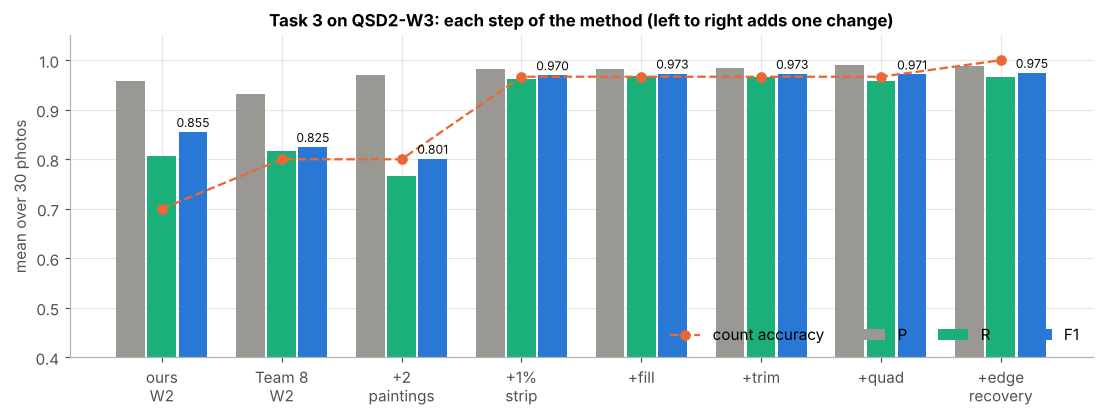

In [23]:
fig, ax = plt.subplots(figsize=(12, 3.8))
x_ = np.arange(len(seg_abl)); lab = [m.split(' · ')[0] for m in seg_abl.method]
for k, (col, c) in enumerate([('QSD2-W3 P', PAL['grey']), ('QSD2-W3 R', PAL['aqua']), ('QSD2-W3 F1', PAL['blue'])]):
    ax.bar(x_ + (k - 1) * 0.26, seg_abl[col], 0.24, color=c, label=col.split()[-1])
ax.plot(x_, seg_abl['QSD2-W3 count accuracy'], 'o--', color=PAL['orange'], label='count accuracy')
for i_, v in enumerate(seg_abl['QSD2-W3 F1']): ax.text(i_ + 0.26, v + 0.01, f'{v:.3f}', ha='center', fontsize=8, color=INK)
ax.set_xticks(x_); ax.set_xticklabels((['ours\nW2', 'Team 8\nW2', '+2\npaintings', '+1%\nstrip', '+fill', '+trim', '+quad', '+edge\nrecovery']))
ax.set_ylim(0.4, 1.05); ax.set_ylabel('mean over 30 photos'); ax.legend(ncol=4, loc='lower right')
ax.set_title('Task 3 on QSD2-W3: each step of the method (left to right adds one change)')
savefig(fig, 't3_ablation')

**What each step does (and why).**
* **0 → 1:** our W2 method keeps only the largest component, so in the 9 photos with two paintings it loses one (low recall and count
  accuracy). Team 8's W2 method, as published, also fails here: its final rule removes the rows/columns with < 50 % painting **in the whole
  image**, which erases paintings that are narrower than half the photo (two paintings side by side).
* **1 → 2:** keeping up to two components (the second must be at least 10 % of the first, to ignore labels) fixes the count.
* **2 → 3:** the **border strip** is the main change of the week. In W3 many paintings are only 1–2 % of the image away from the border, so a
  4 % strip contains painting pixels and the wall model "learns" the painting. A 1 % strip is still thousands of pixels of wall.
* **3 → 6:** per painting post-processing (holes, row/column spans, trimming the thin protrusions that shadows and cables add) and finally
  replacing each region by the **quadrilateral** that fits it (the GT is a quadrilateral too). Each step adds a little precision/recall.
* **6 → 7:** one photo (q2) has a white drawing on white paper on a white wall: the colour model sees only the strokes. Its **frame
  outline** is still visible as edges; regions enclosed by edges that do not overlap a colour detection are added (only when fewer than
  2 paintings were found, and only if nearly rectangular). The count accuracy becomes **1.00**.

### 4.3 Robustness checks: parameters, noise filter and the edge-barrier alternative

In [24]:
t = time.time(); rows = []
VARIANTS = [('final', segment, {}, False), ('final without the noise filter', segment, {}, True),
            ('strip 0.5%', segment, dict(border_ratio=0.005), False), ('strip 2%', segment, dict(border_ratio=0.02), False),
            ('σ = 4.5', segment, dict(sigma=4.5), False), ('σ = 6.5', segment, dict(sigma=6.5), False),
            ('trim 50%', segment, dict(trim=0.5), False), ('axis-aligned box instead of quad', segment, dict(fit='rect'), False),
            ('edges as barriers everywhere (discarded)', segment, dict(edge_barrier=True, recover_edges=False), False)]
for name, fn, kw, raw in VARIANTS:
    o, _ = eval_seg(name, fn, use_raw=raw, **kw); rows.append(o)
seg_var = pd.DataFrame(rows); EXPS['T3 segmentation variants'] = seg_var
print(f'({time.time() - t:.0f}s)'); display(seg_var.set_index('method').round(3))

(34s)


,QSD2-W3 P,QSD2-W3 R,QSD2-W3 F1,QSD2-W3 worst F1,QSD2-W3 count accuracy,QSD2-W2 P,QSD2-W2 R,QSD2-W2 F1,QSD2-W2 worst F1,QSD2-W2 count accuracy,time / photo (s)
method,,,,,,,,,,,
final,0.988,0.965,0.975,0.734,1.000,0.977,0.977,0.977,0.900,1.0,0.069
final without the noise filter,0.988,0.965,0.975,0.734,1.000,0.977,0.977,0.977,0.900,1.0,0.059
strip 0.5%,0.988,0.966,0.975,0.734,1.000,0.977,0.977,0.977,0.900,1.0,0.064
strip 2%,0.987,0.950,0.963,0.684,0.967,0.977,0.977,0.976,0.900,1.0,0.062
σ = 4.5,0.987,0.967,0.975,0.736,1.000,0.973,0.981,0.976,0.901,1.0,0.066
σ = 6.5,0.989,0.964,0.974,0.733,1.000,0.978,0.974,0.976,0.900,1.0,0.062
trim 50%,0.989,0.959,0.971,0.662,1.000,0.978,0.974,0.976,0.898,1.0,0.060
axis-aligned box instead of quad,0.982,0.973,0.976,0.770,1.000,0.973,0.981,0.976,0.894,1.0,0.061
edges as barriers everywhere (discarded),0.971,0.975,0.972,0.851,1.000,0.948,0.988,0.967,0.904,1.0,0.057


**Conclusion 4.3.**
* The method is **stable**: strip 0.5–2 %, σ 4.5–6.5 or a stronger trimming change the F1 by less than 0.01 (we are on a plateau, not on a
  lucky value). A 2 % strip is already slightly worse on W3, for the reason explained above.
* **Without the noise filter** the masks are identical: the segmentation works on a 512-px copy of the photo, and the area-averaging
  downsampling already dissolves the isolated impulses (the same effect we saw in §2.2). The filter is still applied (it costs nothing
  and protects against stronger noise in the test).
* The quadrilateral and the axis-aligned box give the same mean F1 (0.975 vs 0.976); the quadrilateral is more precise (0.988 vs 0.982) and is
  the right model for rotated or perspective views, so we keep it.
* **Edges as barriers everywhere** (the wall flood cannot cross any edge) recovers wall-coloured paintings but **loses precision**: the
  **shadow** under each frame is enclosed between the frame edge and the shadow edge and becomes "painting". That is why edges are only
  used to *add* missing paintings (step 7), never to change the colour detections.

### 4.4 Step by step on one photo, per-photo results and the remaining errors

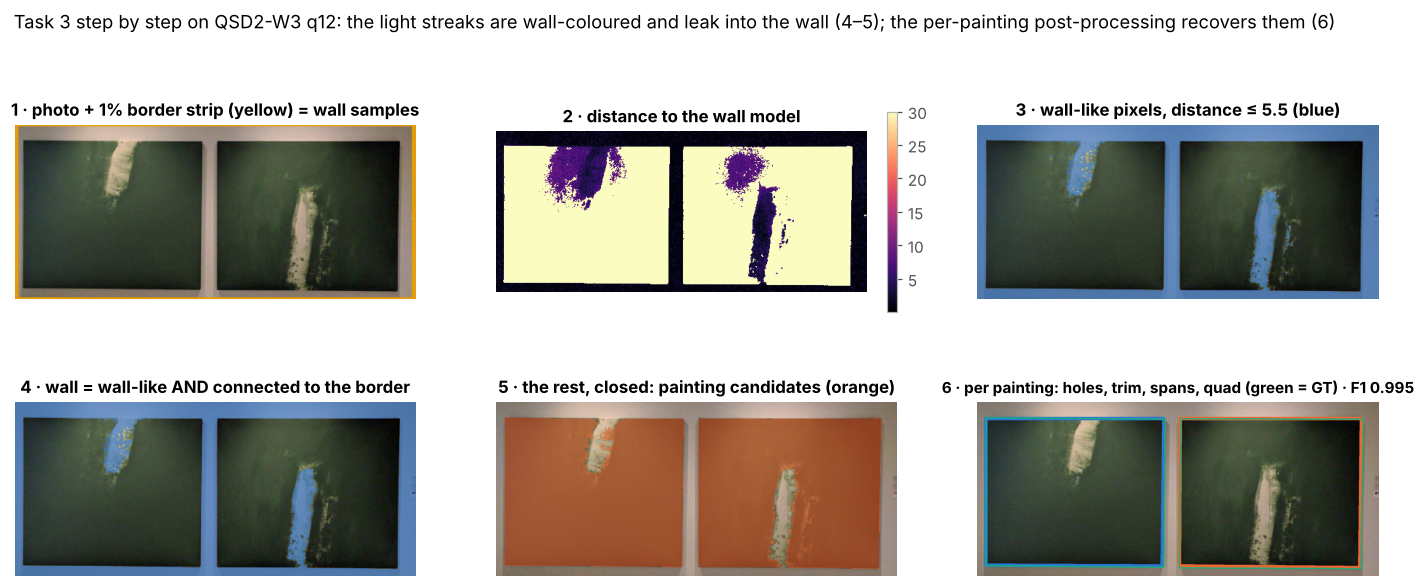

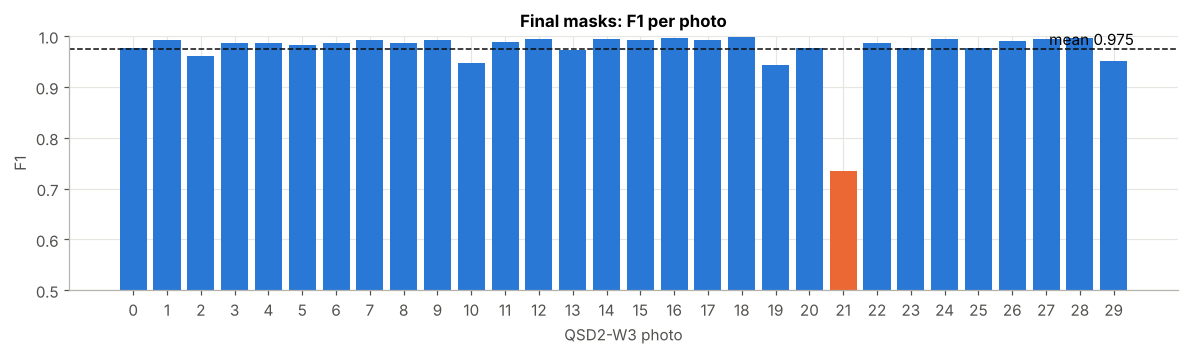

In [25]:
i = 12
u, ms, qs, dbg = segment(Q2[i], debug=True)
sm = cv2.cvtColor(dbg['small'], cv2.COLOR_BGR2RGB); hh, ww = sm.shape[:2]
def tint(img, m, colour, a=0.6):
    out_ = img.copy(); out_[m] = ((1 - a) * out_[m] + a * np.array(colour)).astype(np.uint8); return out_
fig, ax = plt.subplots(2, 3, figsize=(16, 6))
ax[0, 0].imshow(tint(sm, border_strip(hh, ww, 0.01), (237, 161, 0), 0.9)); ax[0, 0].set_title('1 · photo + 1% border strip (yellow) = wall samples')
dv = np.where(np.isinf(dbg['dist']), 30, dbg['dist']); im_ = ax[0, 1].imshow(np.minimum(dv, 30), cmap='magma')
ax[0, 1].set_title('2 · distance to the wall model'); plt.colorbar(im_, ax=ax[0, 1], fraction=0.025)
ax[0, 2].imshow(tint(sm, dbg['wall_like'], (42, 120, 214))); ax[0, 2].set_title('3 · wall-like pixels, distance ≤ 5.5 (blue)')
ax[1, 0].imshow(tint(sm, dbg['wall'], (42, 120, 214))); ax[1, 0].set_title('4 · wall = wall-like AND connected to the border')
ax[1, 1].imshow(tint(sm, dbg['fg'], (235, 104, 52))); ax[1, 1].set_title('5 · the rest, closed: painting candidates (orange)')
res = cv2.cvtColor(Q2[i], cv2.COLOR_BGR2RGB).copy()
for k, q in enumerate(qs):
    cv2.polylines(res, [np.int32(q)], True, (42, 120, 214) if k == 0 else (235, 104, 52), max(4, res.shape[1] // 120))
for ang, pts in Q2_FRAMES[i]: cv2.polylines(res, [np.int32(pts)], True, (27, 175, 122), max(2, res.shape[1] // 300))
ax[1, 2].imshow(res); ax[1, 2].set_title(f'6 · per painting: holes, trim, spans, quad (green = GT) · F1 {prf(u, Q2_MASK[i])[2]:.3f}', fontsize=10)
for a in ax.ravel(): a.axis('off')
fig.suptitle(f'Task 3 step by step on QSD2-W3 q{i}: the light streaks are wall-coloured and leak into the wall (4–5); the per-painting post-processing recovers them (6)', y=1.01)
savefig(fig, 't3_steps')

final_df = seg_detail[ABL[-1][0]]; f3 = final_df[final_df.set == 'QSD2-W3'].reset_index(drop=True)
EXPS['T3 per photo (final)'] = final_df
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(f3.q, f3.F1, color=[PAL['orange'] if f < 0.9 else PAL['blue'] for f in f3.F1])
ax.set_ylim(0.5, 1.0); ax.set_xticks(f3.q); ax.set_xlabel('QSD2-W3 photo'); ax.set_ylabel('F1')
ax.axhline(f3.F1.mean(), color=INK, ls='--', lw=1); ax.text(29.6, f3.F1.mean() + 0.008, f'mean {f3.F1.mean():.3f}', ha='right')
ax.set_title('Final masks: F1 per photo'); savefig(fig, 't3_per_photo')

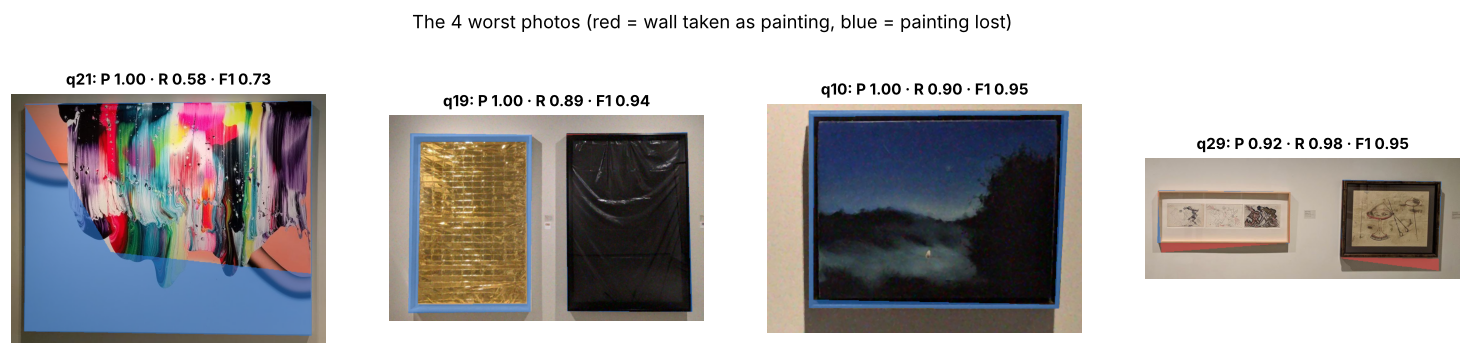

In [26]:
worst = f3.nsmallest(4, 'F1').q.tolist()
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, i in zip(ax, worst):
    u, ms, qs = segment(Q2[i]); vis = cv2.cvtColor(Q2[i], cv2.COLOR_BGR2RGB).copy(); g = Q2_MASK[i]
    vis[u & ~g] = (0.4 * vis[u & ~g] + 0.6 * np.array([227, 73, 72])).astype(np.uint8)        # red: wall taken as painting
    vis[~u & g] = (0.4 * vis[~u & g] + 0.6 * np.array([42, 120, 214])).astype(np.uint8)        # blue: painting lost
    a.imshow(vis); a.axis('off'); p, r, f = prf(u, g); a.set_title(f'q{i}: P {p:.2f} · R {r:.2f} · F1 {f:.2f}', fontsize=10)
fig.suptitle('The 4 worst photos (red = wall taken as painting, blue = painting lost)', y=1.02)
savefig(fig, 't3_worst')

**Conclusion – Task 3.** Final masks on QSD2-W3: see the table (≈ **P 0.99 · R 0.97 · F1 0.975**, all paintings counted correctly), and
≈ **0.977** on QSD2-W2 (vs. 0.954 of our W2 method and 0.976 that Team 8 reported in W2). The remaining errors are understandable:
* **q21:** a canvas whose lower half is the same white as the wall and has no frame: neither colour nor edges can separate it.
* **shadows** under the frames (a few % of precision) and **paper margins/passe-partouts** of the colour of the wall.

**Task 3 method:** denoise → Team 8 wall model with a 1 % border strip → wall = wall-like ∩ connected to the border → up to 2 components
(≥ 2 % of the photo, second ≥ 10 % of the first) → per painting: fill holes, trim sparse rows/cols, row/col span fill, quadrilateral fit
→ edge recovery of wall-coloured paintings when fewer than 2 were found → paintings ordered left to right.

## 5. Task 4 – Retrieval on QSD2-W3 (up to two paintings per photo)

**Pipeline:** photo → Task 1 filter → Task 3 masks → for each painting, **crop** its bounding box → descriptors → ranking.
The answer for each photo is a list with one top-10 list per painting, **in the GT order (left to right)**:
`[[[7, 25, …], [44, 81, …]], [[107, …]], …]` (all ids are Python `int`).

**Evaluation per painting:** the k-th predicted list is compared with the k-th GT painting (AP@K); a painting we did not find counts
as 0. mAP@K is the mean over the 39 paintings.

### 5.1 Why one descriptor is not enough here: combining descriptors (late fusion)

With *our* crops (not the GT ones) the images contain small errors: a strip of wall or shadow, a missing border, a slight rotation.
Each descriptor reacts to different errors: HOG to shifted edges, colour to wall pixels and hue changes, wavelets to scale. When they
**fail on different queries**, combining them should fix the failures. We use **late fusion**: for every query and descriptor, the
distances to the 287 museum images are standardised (z-score: minus their mean, divided by their standard deviation), so that all
descriptors speak the same units, and the standardised distances are added:

$$ d_{\text{fused}}(q, b) = \sum_{k} w_k \,\frac{d_k(q,b) - \mu_k(q)}{\sigma_k(q)} $$

A painting that is the clear winner for one descriptor (very negative z) keeps a good fused score unless another descriptor strongly disagrees.

In [27]:
def zscore(dm): return (dm - dm.mean(1, keepdims=True)) / (dm.std(1, keepdims=True) + EPS)
def fused(imgs, weights):
    tot = 0
    for name, wk in weights.items():
        if wk: tot = tot + wk * zscore(dm_of(name, imgs))
    return tot

def masks_and_crops(img):
    u, ms, qs = segment(img)
    crops = []
    for m in ms:
        x, y, w, h = cv2.boundingRect(m.astype(np.uint8)); crops.append(resize_max(img[y:y + h, x:x + w]))
    return u, ms, qs, crops

def rectify(img, quad):
    # perspective warp of the quadrilateral to a rectangle (alternative to the bounding-box crop)
    q = np.float32(quad); s, d = q.sum(1), np.diff(q, axis=1).ravel()
    o = np.float32([q[np.argmin(s)], q[np.argmin(d)], q[np.argmax(s)], q[np.argmax(d)]])
    w = int(max(np.linalg.norm(o[1] - o[0]), np.linalg.norm(o[2] - o[3]))); h = int(max(np.linalg.norm(o[3] - o[0]), np.linalg.norm(o[2] - o[1])))
    M = cv2.getPerspectiveTransform(o, np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]))
    return resize_max(cv2.warpPerspective(img, M, (w, h)))

t = time.time()
SEG3 = [masks_and_crops(x) for x in Q2]                                     # QSD2-W3 with our masks
CROPS3 = [c for *_, c in SEG3]
RECT3 = [[rectify(Q2[i], q) if q is not None else c for q, c in zip(SEG3[i][2], SEG3[i][3])] for i in range(30)]
SEG2 = [masks_and_crops(img) for img, _ in Q2W2]                             # QSD2-W2 with our masks
CROPS2 = [c for *_, c in SEG2]; GT2W2 = [[g] for g in VAL['QSD2-W2 (GT crop)'][1]] if Q2W2 else []
print(f'segmentation + crops: {time.time() - t:.0f}s · paintings found QSD2-W3: {sum(map(len, CROPS3))} / {sum(map(len, Q2_GT))}')

def eval_multi(photo_crops, gt, weights, k_list=(1, 5)):
    # flatten the photos into paintings: k-th predicted list vs k-th GT painting; a missing painting scores 0
    flat = [c for cr in photo_crops for c in cr]
    order = np.argsort(fused(flat, weights), 1, kind='stable')
    preds, j = [], 0
    for cr in photo_crops: preds.append([[int(b) for b in BB_IDS[order[j + k][:10]]] for k in range(len(cr))]); j += len(cr)
    out = {}
    for K in k_list:
        aps = [apk([g], preds[i][k], K) if k < len(preds[i]) else 0.0 for i in range(len(gt)) for k, g in enumerate(gt[i])]
        out[f'mAP@{K}'] = float(np.mean(aps))
    return out, preds

def eval_crops(imgs, gt_flat, weights):
    order = np.argsort(fused(imgs, weights), 1, kind='stable'); preds = [list(BB_IDS[o[:10]]) for o in order]
    return {f'mAP@{K}': mapk([[g] for g in gt_flat], preds, K) for K in (1, 5)}

segmentation + crops: 4s · paintings found QSD2-W3: 39 / 39


In [28]:
t = time.time()
COMBOS = {'Colour (W2) only': {'Colour (W2)': 1}, 'LBP only': {'LBP': 1}, 'DCT only': {'DCT': 1},
          'Wavelet only': {'Wavelet': 1}, 'HOG only': {'HOG': 1},
          'HOG + colour': {'HOG': 1, 'Colour (W2)': 1}, 'HOG + wavelet': {'HOG': 1, 'Wavelet': 1},
          'Wavelet + colour': {'Wavelet': 1, 'Colour (W2)': 1},
          'HOG + wavelet + colour': {'HOG': 1, 'Wavelet': 1, 'Colour (W2)': 1},
          'HOG + wavelet + DCT + colour': {'HOG': 1, 'Wavelet': 1, 'DCT': 1, 'Colour (W2)': 1},
          'all five': {k: 1 for k in DESCRIPTORS}}
rows = []
for name, wts in COMBOS.items():
    r = {'descriptors': name}
    for s, (imgs, gt) in VAL.items():
        r.update({f'{s} {k}': v for k, v in eval_crops(imgs, gt, wts).items()})
    r.update({f'QSD2-W3 our masks {k}': v for k, v in eval_multi(CROPS3, Q2_GT, wts)[0].items()})
    r.update({f'QSD2-W3 our masks, rectified {k}': v for k, v in eval_multi(RECT3, Q2_GT, wts)[0].items()})
    if Q2W2: r.update({f'QSD2-W2 our masks {k}': v for k, v in eval_multi(CROPS2, GT2W2, wts)[0].items()})
    cols1 = [c for c in r if c.endswith('mAP@1') and 'rectified' not in c]
    r['mean mAP@1 (all sets)'] = np.mean([r[c] for c in cols1]); r['min mAP@1 (all sets)'] = np.min([r[c] for c in cols1])
    rows.append(r)
fusion = pd.DataFrame(rows); EXPS['T4 fusion and retrieval'] = fusion
print(f'({time.time() - t:.0f}s)')
show = ['descriptors', 'QSD1-W3 mAP@1', 'QSD2-W3 (GT crop) mAP@1', 'QSD2-W3 our masks mAP@1', 'QSD2-W3 our masks mAP@5',
        'QSD2-W3 our masks, rectified mAP@1'] + [c for c in fusion.columns if ('W2' in c and c.endswith('mAP@1'))] + ['mean mAP@1 (all sets)', 'min mAP@1 (all sets)']
display(fusion[show].round(3))

(35s)


,descriptors,QSD1-W3 mAP@1,QSD2-W3 (GT crop) mAP@1,QSD2-W3 our masks mAP@1,QSD2-W3 our masks mAP@5,"QSD2-W3 our masks, rectified mAP@1",QSD1-W2 mAP@1,QSD2-W2 (GT crop) mAP@1,QSD2-W2 our masks mAP@1,mean mAP@1 (all sets),min mAP@1 (all sets)
0,Colour (W2) only,0.967,0.897,0.897,0.923,0.923,0.967,1.000,1.000,0.955,0.897
1,LBP only,1.000,0.974,0.872,0.919,0.872,0.967,1.000,1.000,0.969,0.872
2,DCT only,1.000,0.949,0.795,0.852,0.872,0.967,0.967,0.833,0.918,0.795
3,Wavelet only,1.000,0.974,0.974,0.987,0.923,1.000,0.967,0.967,0.980,0.967
4,HOG only,1.000,1.000,0.897,0.906,0.923,1.000,1.000,1.000,0.983,0.897
5,HOG + colour,1.000,1.000,0.974,0.981,1.000,1.000,1.000,1.000,0.996,0.974
6,HOG + wavelet,1.000,1.000,0.949,0.970,0.949,1.000,1.000,1.000,0.991,0.949
7,Wavelet + colour,1.000,0.949,0.949,0.970,0.974,0.967,1.000,1.000,0.977,0.949
8,HOG + wavelet + colour,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
9,HOG + wavelet + DCT + colour,1.000,1.000,1.000,1.000,1.000,0.967,1.000,1.000,0.994,0.967


rank of the correct painting (1 = top) for the paintings where some descriptor fails:


,Colour (W2),Wavelet,HOG,fusion
q2/1,1,1,27,1
q8/1,16,1,1,1
q12/2,2,1,1,1
q19/1,1,2,1,1
q19/2,85,1,1,1
q21/1,1,1,11,1
q24/1,2,1,1,1
q29/1,1,1,57,1
q29/2,1,1,3,1


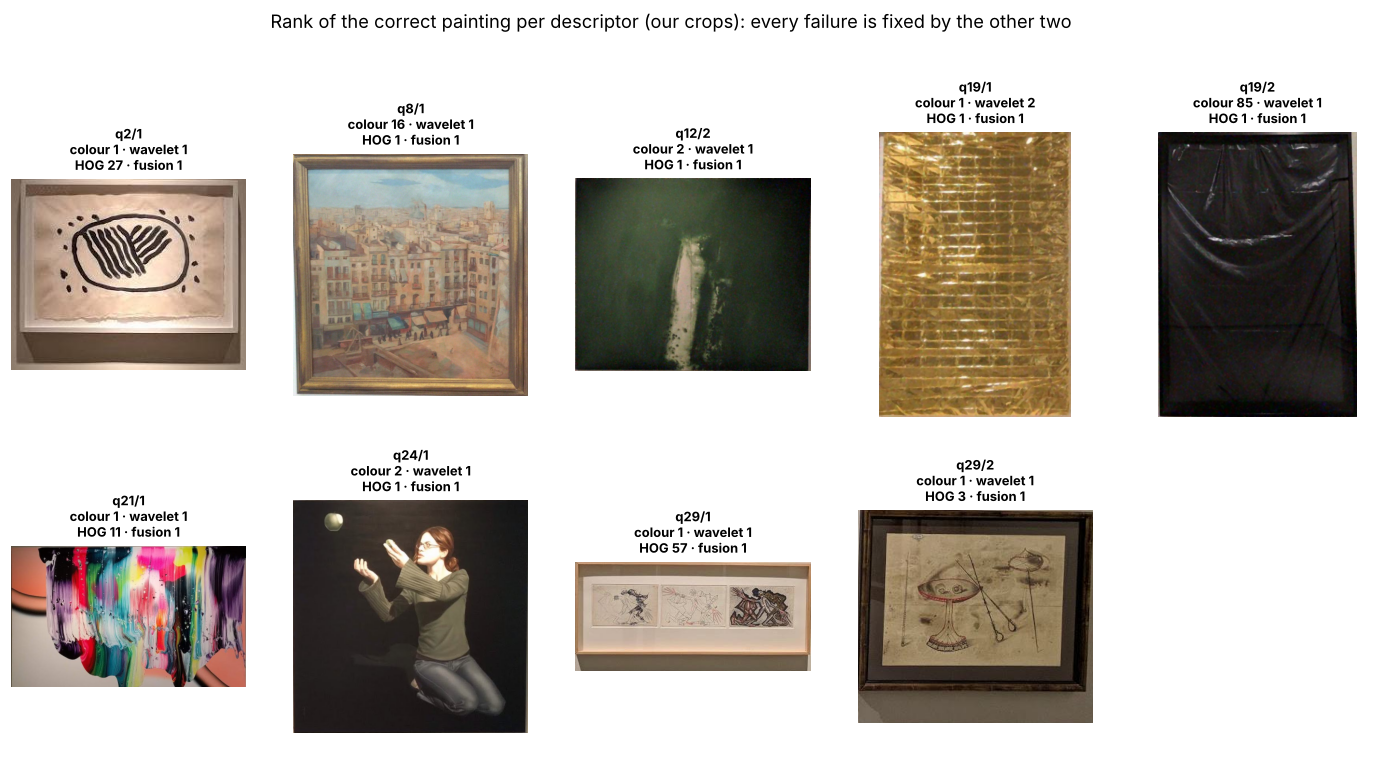

In [29]:
# which paintings does each single descriptor miss on QSD2-W3 with our masks, and what does the fusion do?
flat = [c for cr in CROPS3 for c in cr]; gt_flat = [g for i in range(30) for k, g in enumerate(Q2_GT[i]) if k < len(CROPS3[i])]
src = [(i, k) for i in range(30) for k in range(len(CROPS3[i]))]
R = {n: rank(dm_of(n, flat), gt_flat) for n in ['Colour (W2)', 'Wavelet', 'HOG']}
R['fusion'] = rank(fused(flat, COMBOS['HOG + wavelet + colour']), gt_flat)
rk = pd.DataFrame(R, index=[f'q{i}/{k + 1}' for i, k in src]); EXPS['T4 ranks per painting'] = rk.reset_index().rename(columns={'index': 'painting'})
fails = rk[(rk.drop(columns='fusion') > 1).any(axis=1)]
print('rank of the correct painting (1 = top) for the paintings where some descriptor fails:'); display(fails)

ncol = int(np.ceil(len(fails) / 2))
fig, ax = plt.subplots(2, ncol, figsize=(3.2 * ncol, 7.4))
for a in ax.ravel(): a.axis('off')
for a, (lab, r) in zip(ax.ravel(), fails.iterrows()):
    i, k = src[list(rk.index).index(lab)]
    a.imshow(cv2.cvtColor(CROPS3[i][k], cv2.COLOR_BGR2RGB)); a.axis('off')
    a.set_title(f'{lab}\ncolour {r["Colour (W2)"]} · wavelet {r["Wavelet"]}\nHOG {r["HOG"]} · fusion {r["fusion"]}', fontsize=8.5)
fig.suptitle('Rank of the correct painting per descriptor (our crops): every failure is fixed by the other two', y=1.03)
savefig(fig, 't4_complementary')

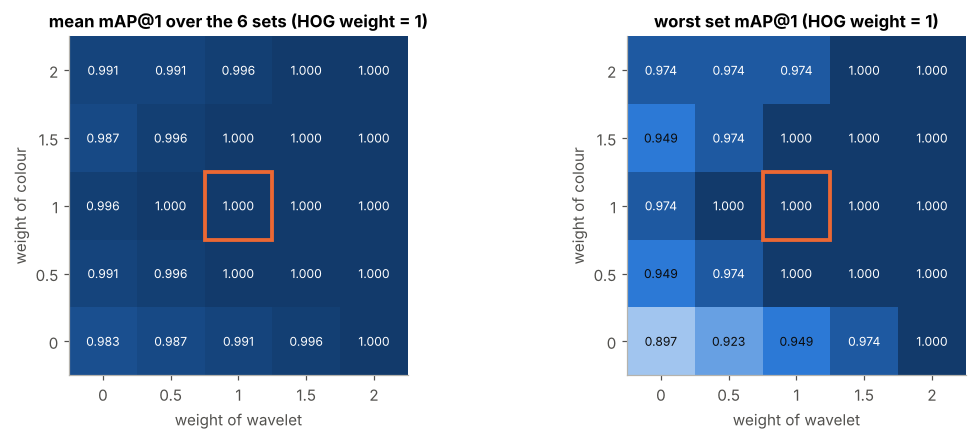

In [30]:
# sensitivity of the fusion weights (HOG weight = 1): is equal weighting a lucky point or a plateau?
ws = [0, 0.5, 1, 1.5, 2]
sets_eval = {s: v for s, v in VAL.items()}
grid_ = np.zeros((len(ws), len(ws))); grid_min = np.zeros_like(grid_)
for a_, wc in enumerate(ws):
    for b_, ww_ in enumerate(ws):
        wts = {'HOG': 1, 'Wavelet': ww_, 'Colour (W2)': wc}
        vals = [eval_crops(imgs, gt, wts)['mAP@1'] for imgs, gt in sets_eval.values()] + [eval_multi(CROPS3, Q2_GT, wts)[0]['mAP@1']]
        if Q2W2: vals.append(eval_multi(CROPS2, GT2W2, wts)[0]['mAP@1'])
        grid_[a_, b_], grid_min[a_, b_] = np.mean(vals), np.min(vals)
EXPS['T4 fusion weights'] = pd.DataFrame([dict(w_colour=wc, w_wavelet=ww_, w_hog=1, mean_mAP1=grid_[a_, b_], min_mAP1=grid_min[a_, b_])
                                          for a_, wc in enumerate(ws) for b_, ww_ in enumerate(ws)])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, G, tt in [(ax[0], grid_, 'mean mAP@1 over the 6 sets'), (ax[1], grid_min, 'worst set mAP@1')]:
    im = a.imshow(G, cmap=SEQ, vmin=0.85, vmax=1, origin='lower'); a.grid(False)
    a.set_xticks(range(len(ws))); a.set_xticklabels(ws); a.set_yticks(range(len(ws))); a.set_yticklabels(ws)
    a.set_xlabel('weight of wavelet'); a.set_ylabel('weight of colour'); a.set_title(f'{tt} (HOG weight = 1)')
    for i_ in range(len(ws)):
        for j_ in range(len(ws)): a.text(j_, i_, f'{G[i_, j_]:.3f}', ha='center', va='center', fontsize=8, color='white' if G[i_, j_] > 0.95 else INK)
    a.add_patch(mpatches.Rectangle((1.5, 1.5), 1, 1, fill=False, ec=PAL['orange'], lw=2.5))
savefig(fig, 't4_fusion_weights')

**Conclusion 5.1.**
* With **GT crops** HOG alone is already perfect, but with **our masks** every single descriptor loses a few paintings (HOG ≈ 0.90, colour
  ≈ 0.90, wavelet ≈ 0.97 on QSD2-W3). The table of ranks shows why fusion works: **the failures do not overlap** (HOG fails where the crop
  includes a strip of wall, colour fails on hue changes and dark paintings, wavelet on a couple of low-contrast ones), so the other two
  descriptors always outvote the one that fails.
* **HOG + wavelet + colour** (equal weights) is the only combination that is **perfect on all six sets** (four GT-crop sets and the two
  QSD2 sets with our masks). Adding DCT (or LBP) adds nothing and loses one QSD1-W2 query.
* The weight map shows a **plateau** around equal weights (orange box): many neighbouring weightings are also perfect, so equal weights
  are not a lucky choice. Without colour (bottom row) or without wavelet (left column) the worst set drops.
* **Rectifying** each painting (perspective warp of its quadrilateral) helps some single descriptors (colour, HOG, DCT) and hurts the wavelet;
  with the fusion both crops give 1.000, so we keep the simpler bounding-box crop (the museum images are not rectified either).

### 5.2 Final result of Task 4 and the output format

,set,what,mAP@1,mAP@5
0,QSD1-W3 (30 queries),"retrieval, final method",1.0,1.0
1,QSD2-W3 (39 paintings),retrieval with our masks (Task 4),1.0,1.0
2,QSD2-W3 (39 paintings),retrieval with GT crops (reference),1.0,1.0


QSD2-W3 masks: precision 0.988 · recall 0.965 · F1 0.975
output format (first 3 photos): [[[236, 141, 212, '…']], [[107, 74, 92, '…']], [[280, 212, 252, '…'], [285, 185, 190, '…']]]


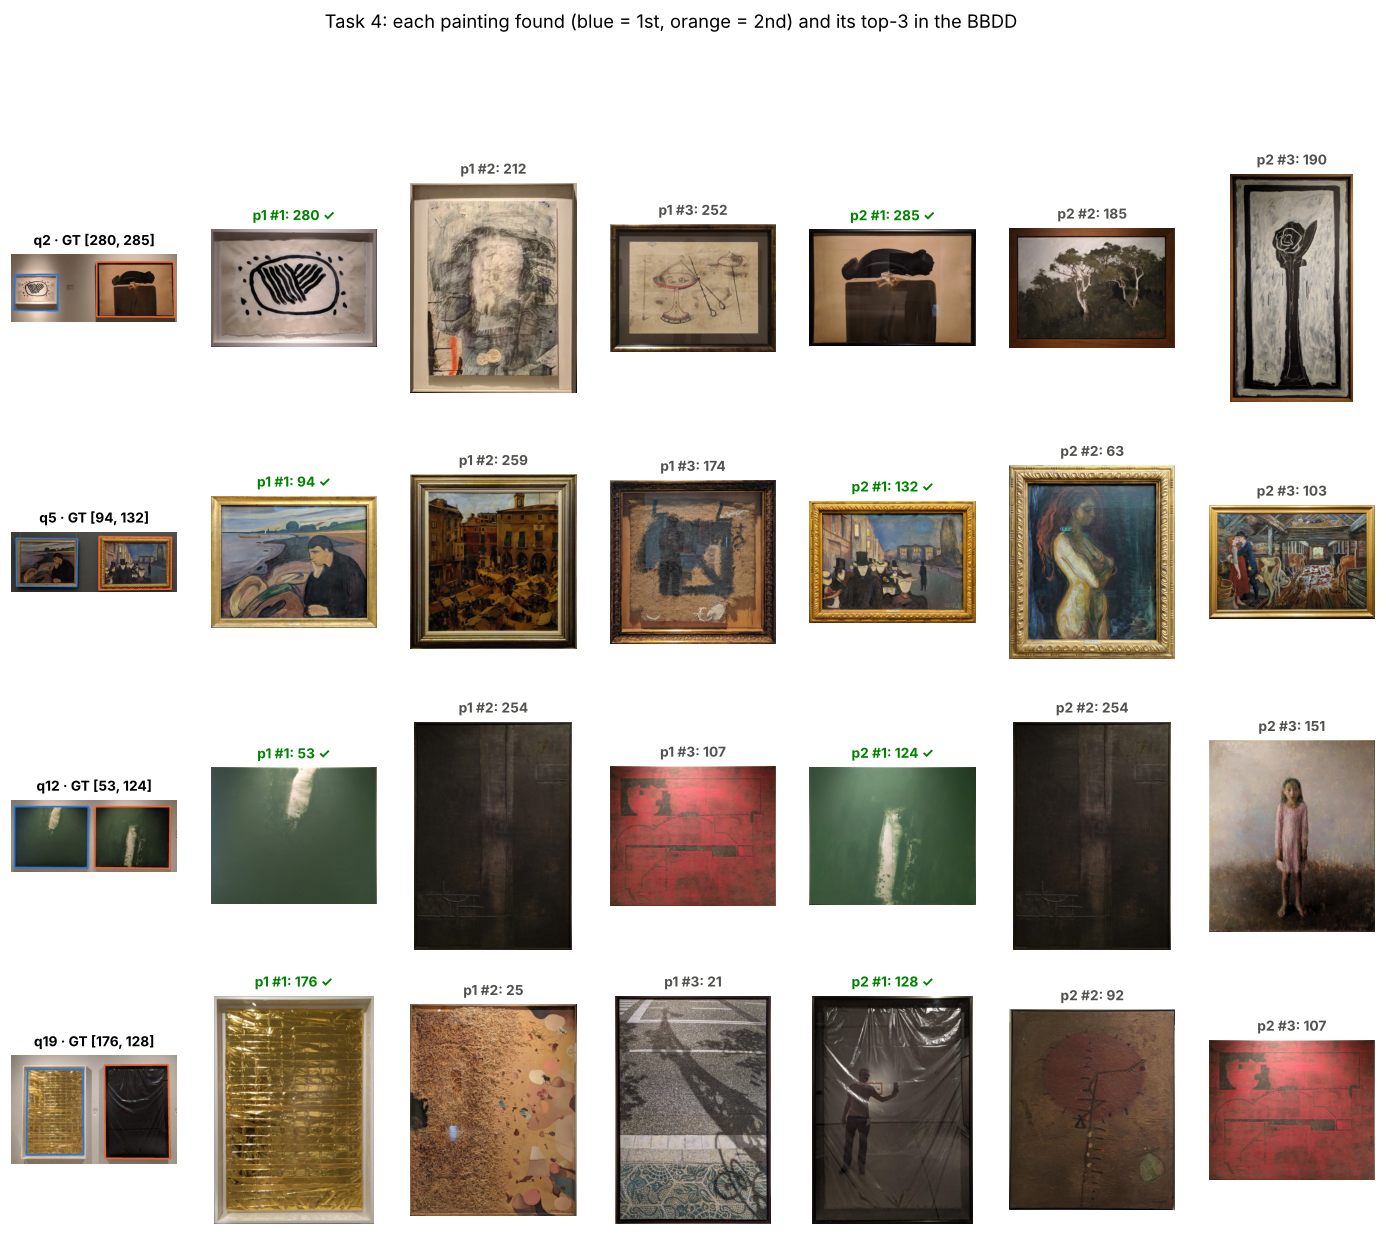

In [31]:
FINAL_WEIGHTS = COMBOS['HOG + wavelet + colour']
res4, PRED_QSD2 = eval_multi(CROPS3, Q2_GT, FINAL_WEIGHTS)
res4_gt = eval_crops(*VAL['QSD2-W3 (GT crop)'], FINAL_WEIGHTS)
res1 = eval_crops(*VAL['QSD1-W3'], FINAL_WEIGHTS)
P, R_, F = np.mean([prf(SEG3[i][0], Q2_MASK[i]) for i in range(30)], 0)
final_table = pd.DataFrame([
    dict(set='QSD1-W3 (30 queries)', what='retrieval, final method', **res1),
    dict(set='QSD2-W3 (39 paintings)', what='retrieval with our masks (Task 4)', **res4),
    dict(set='QSD2-W3 (39 paintings)', what='retrieval with GT crops (reference)', **res4_gt)])
EXPS['Final results'] = final_table
display(final_table.round(3)); print(f'QSD2-W3 masks: precision {P:.3f} · recall {R_:.3f} · F1 {F:.3f}')
print('output format (first 3 photos):', [[p[:3] + ['…'] for p in photo] for photo in PRED_QSD2[:3]])
assert all(type(b) is int for photo in PRED_QSD2 for p in photo for b in p)

# visual: photos with two paintings, our quadrilaterals and the top-3 of each painting
show_i = [2, 5, 12, 19]
fig = plt.figure(figsize=(16, 3.1 * len(show_i)))
for r_, i in enumerate(show_i):
    u, ms, qs, crops = SEG3[i]; vis = cv2.cvtColor(Q2[i], cv2.COLOR_BGR2RGB).copy()
    for k, q in enumerate(qs): cv2.polylines(vis, [np.int32(q)], True, (42, 120, 214) if k == 0 else (235, 104, 52), max(4, vis.shape[1] // 110))
    a = fig.add_subplot(len(show_i), 7, r_ * 7 + 1); a.imshow(vis); a.axis('off'); a.set_title(f'q{i} · GT {Q2_GT[i]}', fontsize=9)
    for k in range(len(crops)):
        for j in range(3):
            b = PRED_QSD2[i][k][j]; a = fig.add_subplot(len(show_i), 7, r_ * 7 + 2 + 3 * k + j)
            a.imshow(cv2.cvtColor(BB[IDX[b]], cv2.COLOR_BGR2RGB)); a.axis('off')
            ok = b == Q2_GT[i][k]; a.set_title(f'p{k + 1} #{j + 1}: {b}' + (' ✓' if ok else ''), fontsize=9, color=PAL['green'] if ok else INK2)
fig.suptitle('Task 4: each painting found (blue = 1st, orange = 2nd) and its top-3 in the BBDD', y=1.0)
savefig(fig, 't4_examples')

**Conclusion – Task 4.** With our own masks the system retrieves **every painting of QSD2-W3 at rank 1** (mAP@1 = mAP@5 = 1.000,
the same as with the GT crops), with the two paintings of each photo returned in the right order and with the extra list level.

## 6. Task 5 – Blind submission (QST1, QST2)

Only **one method** is submitted per test set (method1), the final pipeline of this notebook:

| Step | QST1 (cropped) | QST2 (photos on the wall) |
|---|---|---|
| Noise | detector + median 3×3 twice | same |
| Paintings | the whole image is one painting | Task 3 method, up to 2 paintings, left to right; mask saved as `.png` |
| Descriptors | HOG + Haar wavelet + W2 colour pyramid, z-score fusion | same, on each crop |
| Output | `[[[top-10]], [[top-10]], …]` (extra list level, as the statement asks) | `[[[p1 top-10], [p2 top-10]], …]` |

The test sets are published on Thursday 22 Oct. This cell (and `run_w3.py`, which does the same in < 2 minutes) writes
`results/QST1/method1/result.pkl`, `results/QST2/method1/result.pkl` and `results/QST2/method1/*.png` when `qst1_w3/` and `qst2_w3/` are in this
folder; otherwise it does nothing.

In [32]:
def predict(photos, multi):
    out, masks = [], []
    for img in photos:
        img = denoise(img)[0]
        if multi: u, ms, qs, crops = masks_and_crops(img); masks.append(u)
        else: crops = [resize_max(img)]
        order = np.argsort(fused(crops, FINAL_WEIGHTS), 1, kind='stable')
        out.append([[int(b) for b in BB_IDS[o[:10]]] for o in order])
    return out, masks

def check_format(preds, n):
    assert isinstance(preds, list) and len(preds) == n
    for photo in preds:
        assert isinstance(photo, list) and 1 <= len(photo) <= 2
        for p in photo: assert isinstance(p, list) and len(p) == 10 and len(set(p)) == 10 and all(type(b) is int and 0 <= b < 287 for b in p)

QST1_DIR, QST2_DIR = find_dir('qst1_w3', 'qst_w3/qst1_w3'), find_dir('qst2_w3', 'qst_w3/qst2_w3')
for name, d, multi in [('QST1', QST1_DIR, False), ('QST2', QST2_DIR, True)]:
    if d is None: print(f'{name}: not found (published Thursday 22 Oct) -> skipped'); continue
    paths = jpgs(d); preds, masks = predict([cv2.imread(str(p)) for p in paths], multi); check_format(preds, len(paths))
    outd = Path('results') / name / 'method1'; outd.mkdir(parents=True, exist_ok=True)
    pickle.dump(preds, open(outd / 'result.pkl', 'wb'))
    for p, m in zip(paths, masks): cv2.imwrite(str(outd / f'{p.stem}.png'), m.astype(np.uint8) * 255)
    print(f'{name}: {len(preds)} photos, {sum(map(len, preds))} paintings -> {outd}/result.pkl' + (f' + {len(masks)} masks' if masks else ''))
# sanity check of the same function on the development sets
p1, _ = predict(Q1_RAW, False); p2, _ = predict(Q2_RAW, True)
print(f'dev check · QSD1-W3 mAP@1 {np.mean([apk([g], p[0], 1) for g, p in zip(Q1_GT, p1)]):.3f} · '
      f'QSD2-W3 mAP@1 {np.mean([apk([g], p[k], 1) if k < len(p) else 0 for gg, p in zip(Q2_GT, p2) for k, g in enumerate(gg)]):.3f}')

QST1: not found (published Thursday 22 Oct) -> skipped
QST2: not found (published Thursday 22 Oct) -> skipped


dev check · QSD1-W3 mAP@1 1.000 · QSD2-W3 mAP@1 1.000


## 7. Summary (ready for the slides)

| Task | Method | Result on the development sets |
|---|---|---|
| **1 · Noise** | isolated-impulse detector (r > 0.005, full resolution) + **median 3×3 applied twice** only on the noisy photos | detector 100 % correct on 407 images; SSIM 0.48 → ~0.88 on the noisy photos, clean photos untouched |
| **2 · Texture (QSD1-W3)** | LBP, multi-scale LBP, block DCT, Haar wavelets, HOG on grey 256/128-px squares, per block | **HOG / wavelet / DCT: mAP@1 = mAP@5 = 1.000** (texture only); HOG 1.000 on all 129 dev paintings |
| **3 · Masks (QSD2-W3)** | Team 8's wall model (lightness-conditioned chroma) with a 1 % strip, up to 2 paintings, per-painting post-processing, quadrilateral fit, edge recovery | **P ≈ 0.99 · R ≈ 0.97 · F1 ≈ 0.975**, 30/30 photos with the right number of paintings |
| **4 · Retrieval (QSD2-W3)** | masks → crops → **HOG + wavelet + W2 colour**, z-score late fusion | **mAP@1 = mAP@5 = 1.000** (39 paintings) |
| **5 · Test** | the same pipeline (`run_w3.py`), method1 | QST1 / QST2 pickles + QST2 masks |

**Key messages for the presentation**
1. *Know your noise before filtering:* the difference with the originals shows impulse noise → median (non-linear) beats linear filters,
   and a detector avoids blurring the clean photos.
2. *Texture is immune to the hue change:* grey-level descriptors do not care about the colour rotation that breaks colour histograms.
3. *Blocks again:* every texture descriptor needs a spatial grid (as colour did in W2); HOG's local normalisation makes it the most robust.
4. *Learn from the class:* the best masks of W2 (Team 8) + a thin border strip + per-painting processing = top masks with two paintings.
5. *Complementary descriptors:* on our own crops each descriptor fails on different paintings; z-score fusion of texture + colour fixes all.

**Limits we know of:** a canvas of the same colour as the wall without frame (q21); shadows under the frames; the test sets may contain
stronger noise or hue changes than the development sets (the detector threshold has a ×2 margin on each side; texture is hue-invariant).

In [33]:
# ---- export every experiment table to Excel (one sheet per experiment + a summary sheet)
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
HEAD = PatternFill('solid', fgColor='1F5C99'); BEST = PatternFill('solid', fgColor='C6EFCE'); TITLE = Font(bold=True, size=13, color='1F5C99')
NOTES = {
    'Final results': 'Final method1: denoise -> (QSD2: Task 3 masks + bbox crop) -> HOG + Haar wavelet + W2 colour pyramid, z-score late fusion (equal weights).',
    'T1 noise characterisation': 'Notebook §2.1. Difference between each query and its original (non_augmented/).',
    'T1 noise detector': 'Notebook §2.2. r = fraction of isolated impulses (|I - max/min of the 8 neighbours| > 40), full resolution. Threshold 0.005.',
    'T1 filters PSNR-SSIM': 'Notebook §2.3. Each filter applied to the noisy (16) and clean (14) photos; PSNR / SSIM against the original.',
    'T1 filters summary': 'Notebook §2.3. Means of the previous sheet. Chosen: median 3x3 twice (only on detected noisy photos).',
    'T2 LBP': 'Notebook §3.1. Uniform LBP on a 256x256 grey square, per-block histograms. mAP on the 4 dev sets (GT crops).',
    'T2 DCT': 'Notebook §3.2. Block DCT of a 256x256 grey square, zig-zag, first N coefficients, L2.',
    'T2 wavelet': 'Notebook §3.3. Haar wavelet, per sub-band and block: mean|c| and std; standardised approximation. L1.',
    'T2 HOG': 'Notebook §3.4. skimage HOG on a grey square, L2-normalised.',
    'T2 best descriptors': 'Notebook §3.5. Best configuration of each family vs our W2 colour descriptor. "no filter" = without the Task 1 filter.',
    'T2 per augmentation': 'Notebook §3.5. QSD1-W3 split by augmentation type; input = original photo / noisy query without filter / with filter.',
    'T3 segmentation ablation': 'Notebook §4.2. Each row adds one change. Mean P/R/F1 over the photos (pixel level); count accuracy = right number of paintings.',
    'T3 segmentation variants': 'Notebook §4.3. Robustness of the final method to its parameters; the edge-barrier variant is discarded.',
    'T3 per photo (final)': 'Notebook §4.4. Final masks, per photo.',
    'T4 fusion and retrieval': 'Notebook §5.1. Late fusion (sum of per-query z-scored distances). "our masks" = Task 4 pipeline (crops from our masks).',
    'T4 ranks per painting': 'Notebook §5.1. Rank of the correct painting on QSD2-W3 with our masks, per descriptor and fused.',
    'T4 fusion weights': 'Notebook §5.1. Weights of colour and wavelet with HOG = 1; mean and worst mAP@1 over the 6 evaluation sets.',
}
def write_sheet(ws, title, note, df):
    ws['A1'] = title; ws['A1'].font = TITLE; ws['A2'] = note; ws['A2'].alignment = Alignment(wrap_text=False)
    df = df.copy()
    for c in df.columns:
        if df[c].dtype == object: df[c] = df[c].astype(str)
    for j, c in enumerate(df.columns, 1):
        cell = ws.cell(row=4, column=j, value=str(c)); cell.font = Font(bold=True, color='FFFFFF'); cell.fill = HEAD
        cell.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
    for i, row in enumerate(df.itertuples(index=False), 5):
        for j, v in enumerate(row, 1):
            if isinstance(v, (np.floating, float)): v = None if np.isnan(v) else (float(v) if np.isfinite(v) else 'inf')
            elif isinstance(v, (np.integer,)): v = int(v)
            elif isinstance(v, (np.bool_,)): v = bool(v)
            cell = ws.cell(row=i, column=j, value=v)
            if isinstance(v, float): cell.number_format = '0.000'
    for j, c in enumerate(df.columns, 1):                      # highlight the best value of every metric column
        if any(k in str(c) for k in ['mAP', 'MRR', 'F1', 'SSIM', 'PSNR', 'accuracy']) and pd.api.types.is_numeric_dtype(df[c]) and len(df) > 1:
            v = df[c].replace([np.inf, -np.inf], np.nan)
            if v.notna().any():
                for i in np.where(v == v.max())[0]: ws.cell(row=5 + i, column=j).fill = BEST
        ws.column_dimensions[get_column_letter(j)].width = max(10, min(34, len(str(c)) * 0.9))
    ws.row_dimensions[4].height = 45; ws.freeze_panes = 'B5'

wb = Workbook(); ws = wb.active; ws.title = 'Summary'
ws['A1'] = 'C1 – Week 3 · Team 4 · Summary of results'; ws['A1'].font = TITLE
ws['A2'] = ('All values come from c1-week3.ipynb. Validation: QSD1-W3 (30), QSD2-W3 GT crops (39), QSD1-W2 (30), QSD2-W2 GT crops (30) '
            '+ QSD2-W3 / QSD2-W2 cropped with OUR masks. Green = best value of the column in each sheet.')
summary = pd.concat([final_table.assign(task='Retrieval'),
                     pd.DataFrame([dict(task='Masks QSD2-W3', set='QSD2-W3', what='Task 3 final method', **{'precision': P, 'recall': R_, 'F1': F})])], ignore_index=True)
write_sheet(ws, 'C1 – Week 3 · Team 4 · Summary of results', ws['A2'].value, summary)
for k, (name, df) in enumerate(EXPS.items(), 1):
    if name == 'Final results': continue
    write_sheet(wb.create_sheet(f'{k}. {name}'[:31]), name, NOTES.get(name, ''), df.reset_index(drop=True) if not isinstance(df.index, pd.RangeIndex) else df)
wb.save('C1_W3_all_tests.xlsx')
print('saved C1_W3_all_tests.xlsx with', len(wb.sheetnames), 'sheets ·', f'total run time {(time.time() - T0) / 60:.1f} min')

saved C1_W3_all_tests.xlsx with 17 sheets · total run time 22.2 min
